<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/taller1_pronostico_ocupados.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook construye y evalúa modelos de pronóstico para el número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia, con el objetivo de pronosticar los próximos 6 meses. Se comparan tres familias de modelos sobre la misma serie: promedios móviles con distintos tamaños de ventana, suavización exponencial con distintas configuraciones y regresión lineal con distintas formas de representar la tendencia y la estacionalidad.

Todos los modelos se evalúan con el mismo esquema: una validación que respeta el orden temporal de los datos, con las mismas métricas y los mismos cortes, y una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado.

### Contenido

**Preparación común**

1. **Carga de paquetes:** librerías y versiones del entorno.
2. **Carga y exploración de los datos:** periodo, valores faltantes y comportamiento general de la serie.
3. **Partición de entrenamiento y prueba:** los últimos 6 meses se reservan como prueba.
4. **Componentes de la serie y tipo de estacionalidad:** descomposición de la serie y elección entre estacionalidad aditiva y multiplicativa.
5. **Esquema de validación y modelos de referencia:** validación con origen móvil, métricas y pronósticos naive que todo modelo debe superar.

**Parte I — Promedios móviles y suavización exponencial**

6. **Promedios móviles:** ventanas de distinto tamaño.
7. **Suavización exponencial:** configuraciones de SES, Holt y Holt-Winters, estimadas con toda la historia y con ventanas de los años más recientes, y elección del mejor modelo de esta familia.

**Parte II — Regresión lineal**

8. **Regresión con tendencia:** tendencias polinómicas del tiempo.
9. **Tendencia y estacionalidad con variables dummy:** efectos de mes y revisión de tendencias de mayor grado.
10. **Ventana móvil frente a ventana recursiva:** estimación con los años más recientes.
11. **Estacionalidad con términos de Fourier:** representación del patrón estacional con ondas.
12. **Estacionalidad multiplicativa:** regresión sobre el logaritmo de la serie.
13. **Selección del modelo de regresión.**
14. **Evaluación de los supuestos de los residuales** del modelo de regresión elegido.

**Parte III — Comparación final, prueba y pronóstico**

15. **Comparación de los mejores modelos:** mejor modelo de cada familia en la validación y elección del modelo final.
16. **Evaluación en la muestra de prueba:** desempeño de los modelos finalistas en enero a junio de 2019.
17. **Pronóstico de los próximos 6 meses:** pronóstico de julio a diciembre de 2019 con sus intervalos de predicción.
18. **Conclusiones y limitaciones.**

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Después de cargar los paquetes se imprimen las versiones del entorno. Los modelos de suavización exponencial se estiman por máxima verosimilitud con un optimizador numérico, por lo que sus parámetros y errores pueden variar levemente entre sistemas operativos o procesadores, aun con las mismas versiones de las librerías. La regresión por mínimos cuadrados, en cambio, tiene una solución cerrada, por lo que sus coeficientes y errores deberían coincidir entre sistemas, salvo diferencias en los últimos decimales.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# Validación y métricas
from sklearn.model_selection import TimeSeriesSplit                # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Descripción de la serie y modelos
from statsmodels.tsa.seasonal import seasonal_decompose            # descomposición (solo para describir la serie)
from statsmodels.tsa.exponential_smoothing.ets import ETSModel     # suavización exponencial (SES, Holt, Holt-Winters)
import statsmodels.api as sm                                       # regresión lineal por MCO y gráfico Q-Q

# Supuestos de los residuales de la regresión
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch  # autocorrelación y efectos ARCH
from statsmodels.sandbox.stats.runs import runstest_1samp          # prueba de rachas
from statsmodels.graphics.tsaplots import plot_acf                 # ACF de los residuales
from scipy import stats                                            # Jarque-Bera, Shapiro-Wilk y curva normal

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5


## 2. Carga y exploración de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Para este análisis se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas. Antes de construir los modelos, se revisa el periodo cubierto, si hay valores faltantes y el comportamiento general de la serie, para identificar su tendencia y su estacionalidad, de las que depende la elección y la configuración de los modelos.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


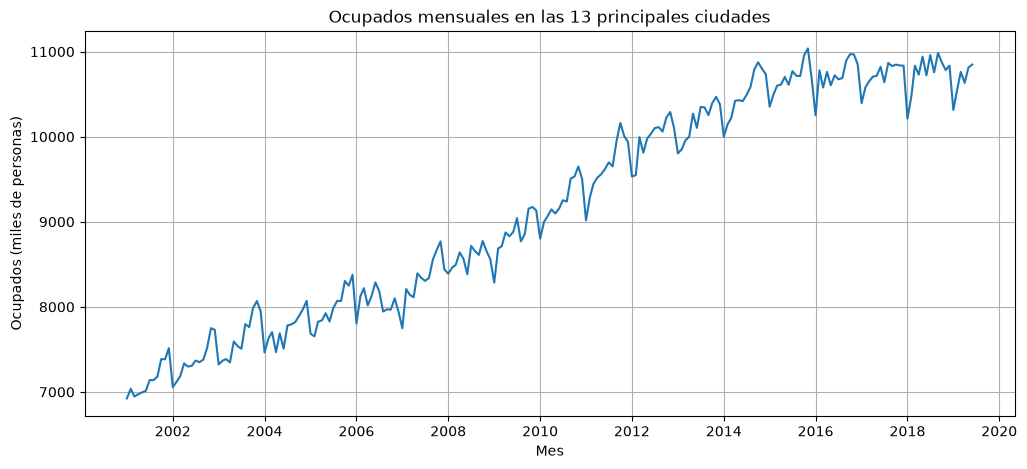

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante, y además evita la advertencia de frecuencia de statsmodels.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil.

- **Tendencia:** la serie crece de forma casi lineal entre 2001 y 2015, de cerca de 7 millones a cerca de 10.7 millones de ocupados. Desde 2016 el crecimiento se detiene y la serie se mantiene entre 10.2 y 11 millones. La tendencia, por lo tanto, no es constante: cambia de pendiente en los últimos años.
- **Estacionalidad:** todos los años se repite el mismo patrón. Los ocupados alcanzan sus valores más altos en el último trimestre del año y caen bruscamente en enero, para luego recuperarse durante los meses siguientes. Este patrón coincide con el de la tasa de desempleo, que sube cada enero, y es compatible con la terminación de empleos temporales de fin de año, aunque los datos no permiten verificar esa causa.
- **Tamaño de la oscilación:** en la gráfica, la caída de enero parece hacerse más profunda a medida que aumenta el nivel de la serie. Esto sugiere que el efecto estacional podría ser proporcional al nivel, es decir, multiplicativo, algo que se revisará con los datos de entrenamiento.
- **Componente irregular:** además de la tendencia y la estacionalidad, la serie presenta fluctuaciones de un mes a otro sin un patrón claro.

Estas características orientan la elección de los modelos. Los promedios móviles y la suavización exponencial simple no capturan la tendencia ni la estacionalidad, por lo que sirven como referencia. Los modelos de Holt-Winters y la regresión con variables de mes sí pueden capturar la estacionalidad. El cambio de pendiente de los últimos años afecta a ambos: en Holt-Winters hace necesario comparar configuraciones con y sin tendencia, y en la regresión, un polinomio del tiempo estimado con toda la historia no puede representar el cambio sin curvarse de forma poco realista al extenderse hacia el futuro.

## 3. Partición de entrenamiento y prueba

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie se reservan como muestra de prueba: de enero a junio de 2019. Así, la evaluación final mide el desempeño de los modelos en el mismo horizonte en el que se usarán. El resto de la serie, de enero de 2001 a diciembre de 2018, forma la muestra de entrenamiento.

La partición respeta el orden temporal: todos los datos de entrenamiento son anteriores a los de prueba. Además, la muestra de prueba no se usa para tomar ninguna decisión de modelado, como el tamaño de la ventana de un promedio móvil, la configuración de la suavización exponencial, el grado de la tendencia de la regresión o la elección del modelo final. Esas decisiones se toman solo con el entrenamiento, para que el error en la prueba sea una estimación honesta del desempeño del modelo con datos que no ha visto.

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


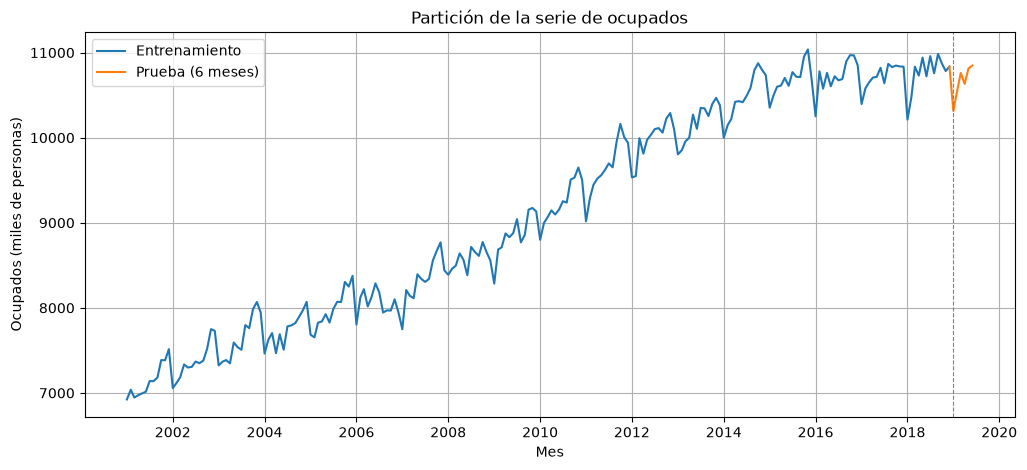

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

# Gráfica de la partición. La línea de prueba se dibuja desde el último mes de
# entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), label="Prueba (6 meses)", color="C1")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Partición de la serie de ocupados")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend()
ax.grid()
plt.show()

La muestra de entrenamiento tiene 216 meses, de enero de 2001 a diciembre de 2018, y la de prueba 6 meses, de enero a junio de 2019. La prueba comienza con la caída estacional de enero y continúa con la recuperación de los meses siguientes, de modo que permite evaluar si los modelos capturan el patrón estacional de la serie y no solo su nivel.

## 4. Componentes de la serie y tipo de estacionalidad

Antes de construir los modelos, la serie de entrenamiento se descompone en tendencia, estacionalidad y residuo. La descomposición no se usa para pronosticar, sino para orientar tres decisiones comunes a la suavización exponencial y a la regresión: cómo tratar la tendencia, cómo representar el patrón estacional y si el efecto de cada mes es una cantidad fija de personas (estacionalidad aditiva) o un porcentaje del nivel de la serie (estacionalidad multiplicativa).

La última decisión se incorpora de forma distinta en cada familia de modelos. En Holt-Winters, el componente estacional se define directamente como aditivo o multiplicativo. Una regresión lineal, en cambio, solo suma sus componentes; si la estacionalidad es multiplicativa, $y_t = T_t \cdot S_t \cdot R_t$, la regresión se ajusta sobre el logaritmo de la serie, donde los componentes se suman: $\log y_t = \log T_t + \log S_t + \log R_t$. Para orientar la elección, se descompone la serie con ambos supuestos y se comparan sus residuos: el supuesto adecuado es el que deja un residuo sin patrón. Se usa solo el entrenamiento para que estas decisiones no dependan de la muestra de prueba.

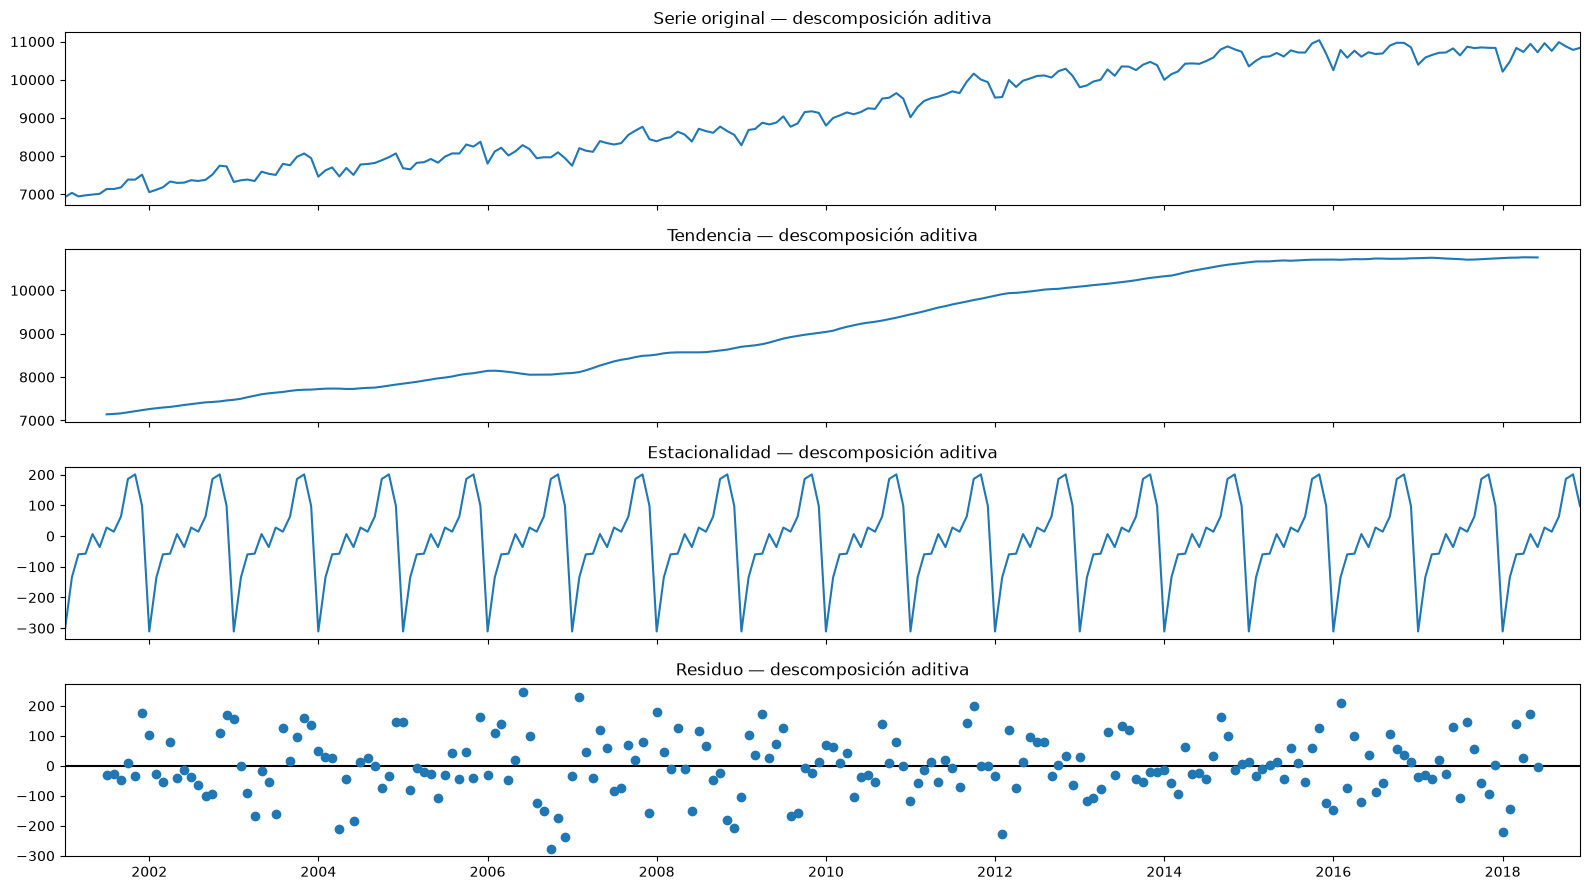

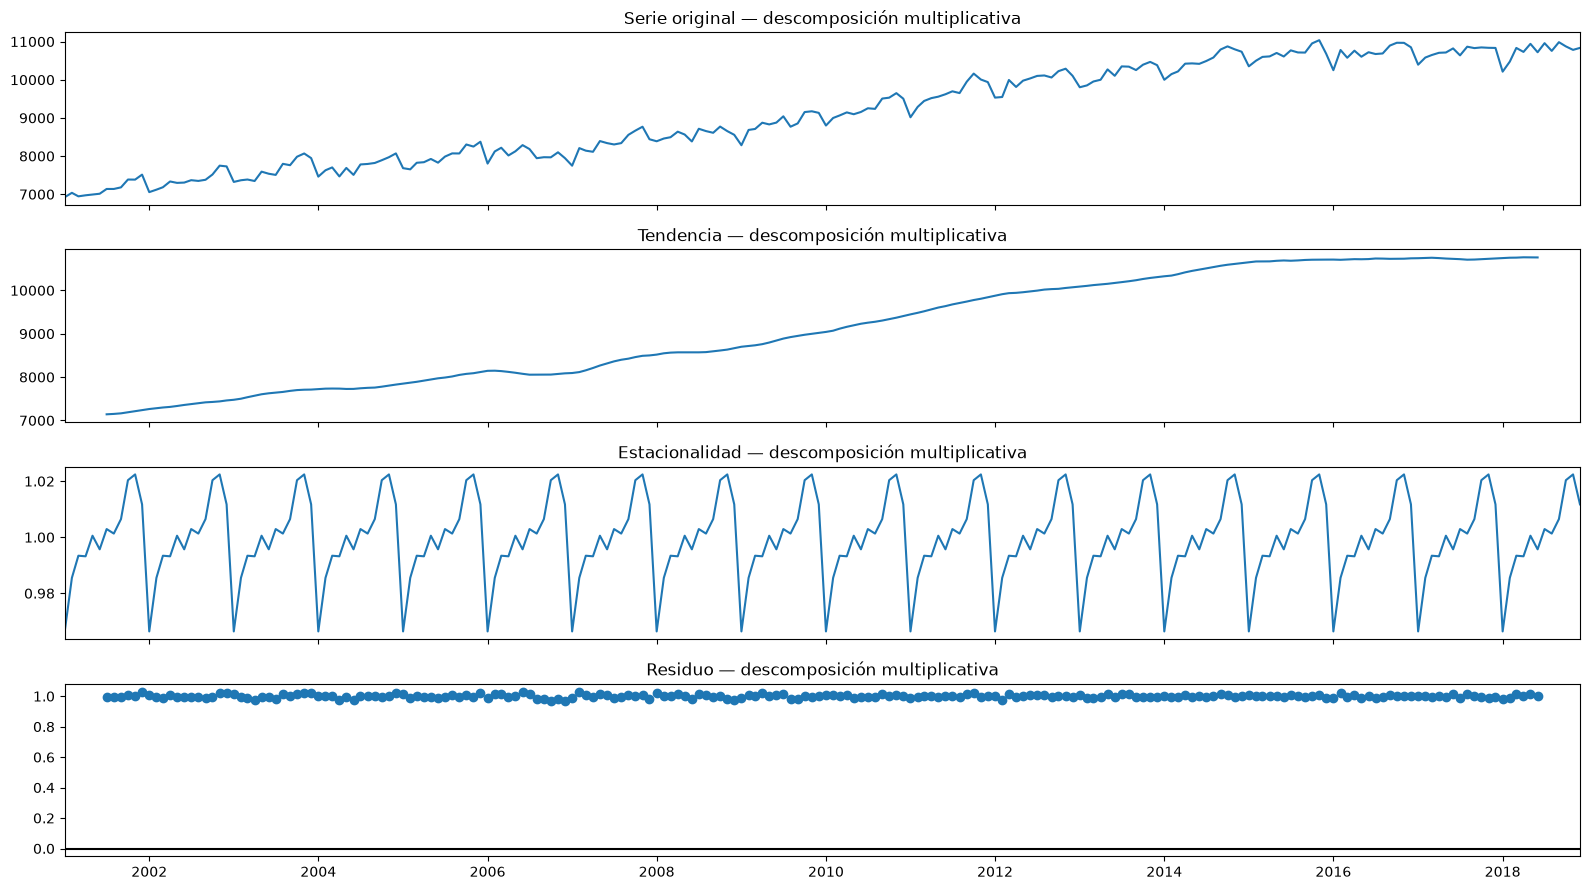

     Aditivo (miles de personas)  Multiplicativo (factor)
Ene                     -310.479                    0.966
Feb                     -134.241                    0.986
Mar                      -59.495                    0.993
Abr                      -57.295                    0.993
May                        6.527                    1.001
Jun                      -35.769                    0.996
Jul                       27.708                    1.003
Ago                       14.336                    1.001
Sep                       63.805                    1.006
Oct                      185.986                    1.020
Nov                      200.802                    1.022
Dic                       98.116                    1.012


In [6]:
# Descomposición clásica del entrenamiento con ambos supuestos
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")

# Gráficas de ambas descomposiciones, con títulos en español
titulos = ["Serie original", "Tendencia", "Estacionalidad", "Residuo"]
for desc, nombre in [(desc_aditiva, "aditiva"), (desc_multiplicativa, "multiplicativa")]:
    fig = desc.plot()
    fig.set_size_inches((16, 9))
    for eje, titulo in zip(fig.axes, titulos):
        eje.set_title(f"{titulo} — descomposición {nombre}")
        eje.set_ylabel("")
    fig.tight_layout()
    plt.show()

# Efecto estacional estimado para cada mes con ambos supuestos
# (el entrenamiento empieza en enero, así que las primeras 12 filas van de enero a diciembre)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles de personas)": desc_aditiva.seasonal.iloc[:12].values,
    "Multiplicativo (factor)": desc_multiplicativa.seasonal.iloc[:12].values,
}, index=nombres_meses)
print(efectos_estacionales.round(3))

### Componentes de la serie de entrenamiento

Las dos figuras muestran la descomposición de la serie de entrenamiento con cada supuesto. Cada una tiene cuatro paneles: la serie original, la tendencia, la estacionalidad y el residuo. Bajo el supuesto aditivo, la serie es la suma de las tres piezas (tendencia + estacionalidad + residuo); bajo el multiplicativo, es su producto (tendencia × estacionalidad × residuo).

**Tendencia.** Ambas descomposiciones estiman la misma tendencia, porque las dos la calculan con el mismo promedio móvil centrado de 12 meses. Por esa misma razón, la tendencia no está disponible en los primeros ni en los últimos 6 meses del entrenamiento. Los ocupados crecen de cerca de 7,150 mil a mediados de 2001 a cerca de 10,700 mil en 2015, con una breve pausa entre 2006 y 2007, y desde 2015 se mantienen prácticamente estables hasta 2018. Para los modelos, esto significa que una tendencia estimada con toda la historia tendrá una pendiente positiva que no corresponde a los últimos años: en Holt-Winters, una tendencia lineal extendería ese crecimiento hacia el futuro, y en la regresión, un polinomio de grado bajo tendrá la misma pendiente, mientras que uno de grado mayor puede aproximar el aplanamiento, pero también extenderlo hacia una caída o una subida que los datos no muestran.

**Estacionalidad.** Ambas descomposiciones encuentran el mismo patrón, repetido de forma idéntica todos los años, porque la descomposición clásica supone un único patrón estacional. Lo que cambia es la forma de medirlo:

| Mes | Efecto aditivo (miles de personas) | Efecto multiplicativo |
|---|---|---|
| Enero | -310 | 0.966 (3.4 % por debajo de la tendencia) |
| Febrero | -134 | 0.986 (1.4 % por debajo) |
| Octubre | +186 | 1.020 (2.0 % por encima) |
| Noviembre | +201 | 1.022 (2.2 % por encima) |
| Diciembre | +98 | 1.012 (1.2 % por encima) |

Los ocupados caen con fuerza en enero, se recuperan gradualmente entre febrero y abril, se mantienen cerca de la tendencia a mitad de año y alcanzan sus valores más altos en octubre y noviembre. El patrón no es una onda suave: entre diciembre y enero el efecto pasa de +98 a -310 mil personas, un cambio de 408 mil en un solo mes, mientras que entre mayo y septiembre los efectos varían poco. Esta forma es relevante para la regresión, porque un cambio tan brusco requiere un regresor que permita a cada mes tener su propio efecto, o una combinación de varias ondas de distinta frecuencia.

En el supuesto aditivo, el efecto es una cantidad fija de personas que se suma a la tendencia. En el multiplicativo, es un factor que multiplica la tendencia: un factor de 1.022 equivale a quedar 2.2 % por encima, y uno de 0.966, a quedar 3.4 % por debajo. Por eso, en el multiplicativo el efecto en personas crece con el nivel de la serie. Por ejemplo, la caída de enero sería de 310 mil personas en cualquier año con el supuesto aditivo, mientras que con el multiplicativo sería de cerca de 245 mil cuando la tendencia está en 7,200 mil y de cerca de 364 mil cuando está en 10,700 mil.

**Residuo.** En la descomposición aditiva, el residuo oscila alrededor de 0, casi siempre entre -250 y 250 mil personas, sin una forma que se repita a simple vista, aunque con algunos valores más alejados entre 2006 y 2007, que coinciden con la pausa de la tendencia. En la descomposición multiplicativa, el residuo no puede evaluarse en la gráfica: la función dibuja la línea de referencia en 0, aunque este residuo gira alrededor de 1, así que los valores quedan comprimidos en una franja casi plana. Además, un patrón que afecte solo a un mes puede quedar escondido entre los demás. Por eso, en la siguiente celda se comparan los residuos de enero, el mes con el mayor efecto estacional, con ambos supuestos y en las mismas unidades.

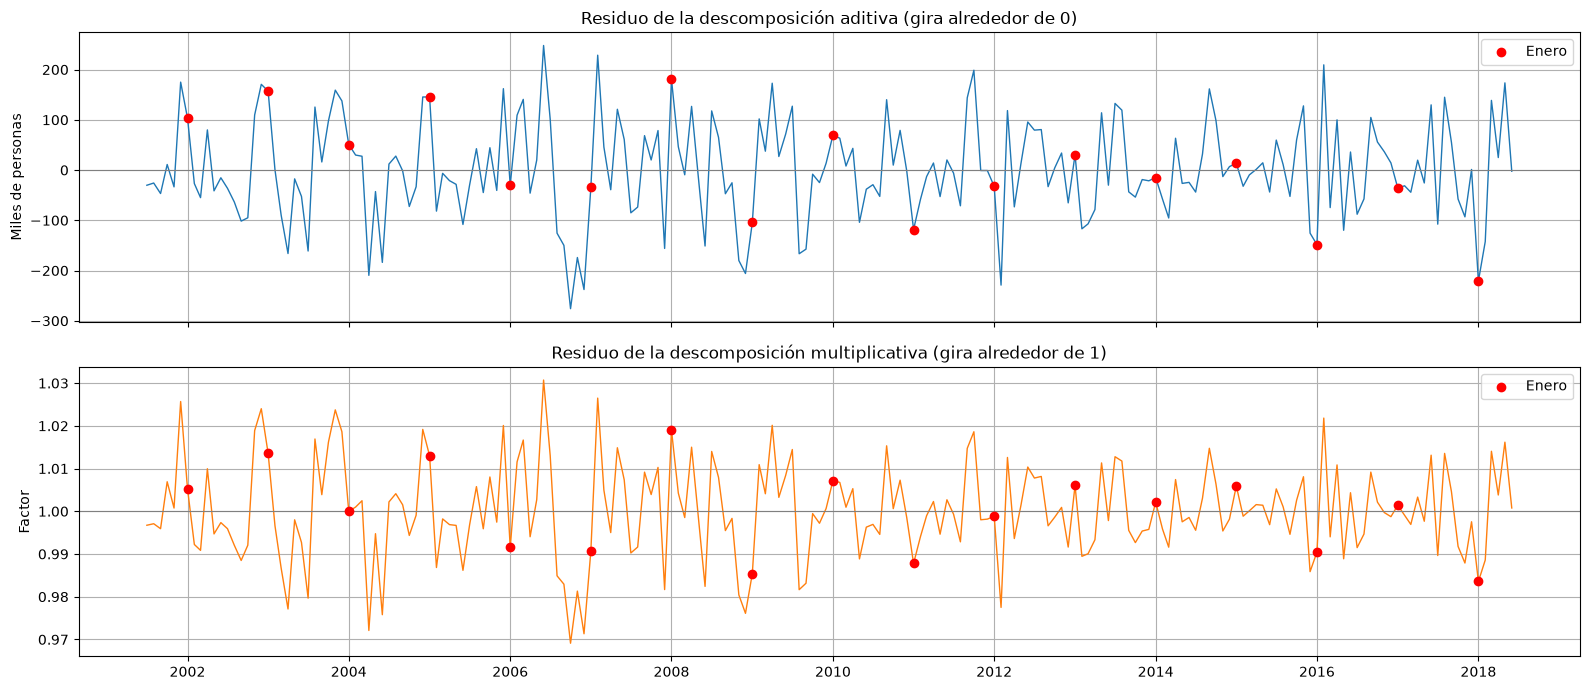

            Tendencia  Residuo aditivo  Residuo multiplicativo  Caída real (miles)  Caída real (%)  Residuo multiplicativo (miles)
mes                                                                                                                               
2002-01-01   7263.377          103.436                   1.005             207.043           2.851                          36.974
2003-01-01   7476.767          157.169                   1.014             153.310           2.050                          97.876
2004-01-01   7722.007           50.852                   1.000             259.627           3.362                          -0.202
2005-01-01   7849.145          145.386                   1.013             165.093           2.103                          98.603
2006-01-01   8144.433          -29.839                   0.992             340.318           4.179                         -66.702
2007-01-01   8093.627          -34.342                   0.991             344.821 

In [7]:
# Comparación de los residuos de enero, el mes con el mayor efecto estacional.
# Si el supuesto es correcto, estos residuos no deben quedar sistemáticamente
# arriba o abajo de la referencia en algún periodo.
es_enero = train.index.month == 1

# Gráfica de ambos residuos en su propia escala, con los eneros resaltados
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axes[0].plot(desc_aditiva.resid, color="C0", linewidth=1)
axes[0].scatter(train.index[es_enero], desc_aditiva.resid[es_enero], color="red", zorder=3, label="Enero")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Residuo de la descomposición aditiva (gira alrededor de 0)")
axes[0].set_ylabel("Miles de personas")
axes[0].legend()
axes[0].grid()

axes[1].plot(desc_multiplicativa.resid, color="C1", linewidth=1)
axes[1].scatter(train.index[es_enero], desc_multiplicativa.resid[es_enero], color="red", zorder=3, label="Enero")
axes[1].axhline(1, color="gray", linewidth=0.8)
axes[1].set_title("Residuo de la descomposición multiplicativa (gira alrededor de 1)")
axes[1].set_ylabel("Factor")
axes[1].legend()
axes[1].grid()

fig.tight_layout()
plt.show()

# Tendencia, residuos y caída real de cada enero.
# La caída real es cuánto quedó enero por debajo de la tendencia en ese año.
eneros = pd.DataFrame({
    "Tendencia": desc_aditiva.trend[es_enero],
    "Residuo aditivo": desc_aditiva.resid[es_enero],
    "Residuo multiplicativo": desc_multiplicativa.resid[es_enero],
})
eneros["Caída real (miles)"] = eneros["Tendencia"] - train[es_enero]
eneros["Caída real (%)"] = 100 * eneros["Caída real (miles)"] / eneros["Tendencia"]

# Residuo multiplicativo expresado en miles para compararlo con el aditivo.
# En el modelo multiplicativo Y = T * S * R, el desvío en miles es T * S * (R - 1).
factor_enero = desc_multiplicativa.seasonal[es_enero]
eneros["Residuo multiplicativo (miles)"] = (
    eneros["Tendencia"] * factor_enero * (eneros["Residuo multiplicativo"] - 1)
)

# Enero de 2001 no tiene tendencia (el promedio móvil centrado pierde los primeros 6 meses)
eneros = eneros.dropna()
print(eneros.round(3).to_string())

comparacion_residuos = eneros[["Residuo aditivo", "Residuo multiplicativo (miles)"]]
print("\nPromedio del valor absoluto del residuo de enero (miles):")
print(comparacion_residuos.abs().mean().round(1).to_string())

print("\nPromedio del residuo de enero por periodo (miles):")
print(pd.DataFrame({
    "2002-2005": comparacion_residuos.loc["2002":"2005"].mean(),
    "2016-2018": comparacion_residuos.loc["2016":"2018"].mean(),
}).round(1).to_string())

### Elección del tipo de estacionalidad

Para decidir entre el supuesto aditivo y el multiplicativo se analizaron los eneros, porque enero es el mes con el mayor efecto estacional: la descomposición aditiva estima una caída fija de 310.5 mil personas frente a la tendencia, y la multiplicativa una caída de 3.4 % (factor de 0.966). Si el supuesto es correcto, los residuos de enero deberían oscilar alrededor de cero sin un patrón en el tiempo. Como los dos residuos están en unidades distintas, el multiplicativo se expresó en miles como $T_t \cdot S_t \cdot (R_t - 1)$, es decir, el valor esperado por el modelo multiplicado por el porcentaje en que se aleja de él.

| Residuo de enero (miles) | Aditivo | Multiplicativo |
|---|---|---|
| Promedio del valor absoluto, 2002-2018 | 87.7 | 74.3 |
| Promedio 2002-2005 | +114.2 | +58.3 |
| Promedio 2016-2018 | -135.0 | -85.0 |

Con el supuesto aditivo hay un sesgo claro. Entre 2002 y 2005, cuando la tendencia estaba entre 7,263 y 7,849 mil, la caída real de enero fue de 153 a 260 mil personas, menor que la estimada, y el residuo queda positivo. En 2016 y 2018, con una tendencia cercana a 10,700 mil, la caída real fue de 459 y 532 mil, mayor que la estimada, y el residuo queda negativo. Es decir, la caída de enero creció con el nivel de la serie, lo que contradice el supuesto aditivo de un efecto fijo en personas.

El supuesto multiplicativo reduce este sesgo, porque una caída en porcentaje se traduce en más personas cuando el nivel es mayor: el error promedio baja de 87.7 a 74.3 mil (cerca de 15 %) y los promedios por periodo se reducen a +58.3 y -85.0 mil. La mejora se concentra en los extremos del periodo, 2002-2005 y 2016-2018, donde el nivel está más lejos del promedio de la serie y los dos supuestos producen caídas más distintas. En cambio, en 2006, 2007, 2009, 2013, 2014 y 2015 el residuo multiplicativo es mayor que el aditivo.

El sesgo, sin embargo, no desaparece. La caída de enero como porcentaje de la tendencia varía bastante de un año a otro, entre 1.5 % y 4.9 %, pero en promedio pasó de 2.6 % en 2002-2005 a 4.2 % en 2016-2018, es decir, creció incluso más que en proporción al nivel. Esto sugiere que el patrón estacional cambió con el tiempo, algo que la descomposición clásica no puede capturar porque supone el mismo efecto para todos los años.

Por lo tanto, el supuesto multiplicativo describe mejor la serie, pero la ventaja es moderada, y la elección final se hará con el error de pronóstico en la validación. En la suavización exponencial se evaluarán configuraciones de Holt-Winters con estacionalidad aditiva y multiplicativa, y en la regresión se ajustarán tanto la serie en su escala original como su logaritmo. Además, es deseable que el modelo refleje el patrón estacional reciente y no solo el promedio de toda la historia. Esto se puede lograr de dos formas: actualizando los efectos estacionales con el tiempo, lo que en Holt-Winters controla el parámetro $\gamma$, o estimando el modelo solo con los años más recientes. Por eso, en las dos familias de modelos se evaluará también el periodo de estimación.

## 5. Esquema de validación y modelos de referencia

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica una validación con origen móvil dentro del entrenamiento. Es la versión de la validación cruzada para series de tiempo: en lugar de partir los datos al azar, se definen varios cortes en el tiempo, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. Ajustar significa volver a estimar los parámetros del modelo, como los parámetros de suavización o los coeficientes de la regresión, solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Se usan 6 cortes, de modo que cada modelo se evalúa en 6 semestres distintos entre 2016 y 2018, y no depende de un solo periodo. En cada corte se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, porque está en las mismas unidades de la serie y castiga con más fuerza los meses en que el pronóstico se aleja mucho del valor real. El MAPE promedio se usa como complemento, y entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre. Las tres familias de modelos se evalúan con los mismos cortes y las mismas métricas, de modo que sus resultados son directamente comparables.

Como referencia se usan dos pronósticos ingenuos. El **naive** repite el último valor observado en los 6 meses, y el **naive estacional** repite el valor del mismo mes del año anterior. Un modelo solo aporta valor si mejora estas referencias.

In [8]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


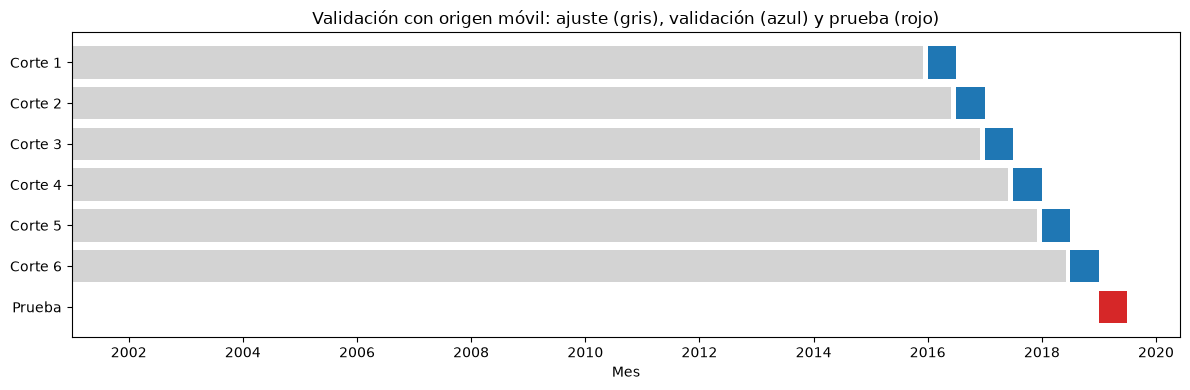

In [9]:
# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses de ajuste; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

El diagrama muestra los 6 cortes de la validación. En cada uno, los datos disponibles para ajustar el modelo van desde enero de 2001 hasta el mes anterior al corte (gris), y el modelo se evalúa en los 6 meses siguientes (azul), de modo que los cortes cubren de forma consecutiva los semestres de 2016 a 2018. La muestra de prueba (rojo) queda por fuera de todos los cortes y solo se usa al final, para evaluar los modelos finalistas.

In [10]:
def calcular_metricas(real, pronostico):
    """RMSE (miles de personas) y MAPE (%) de un pronóstico frente a los valores reales."""
    return {
        "rmse": np.sqrt(mean_squared_error(real, pronostico)),
        # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
        "mape": 100 * mean_absolute_percentage_error(real, pronostico),
    }


def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    Devuelve una tabla con el RMSE (miles) y el MAPE (%) de cada corte.
    """
    filas = []
    for idx_ajuste, idx_validacion in cv.split(serie):
        serie_ajuste = serie.iloc[idx_ajuste]
        serie_validacion = serie.iloc[idx_validacion]
        pronostico = funcion_pronostico(serie_ajuste, len(serie_validacion))
        filas.append({
            "inicio_validacion": serie_validacion.index[0].strftime("%Y-%m"),
            **calcular_metricas(serie_validacion, pronostico),
        })
    return pd.DataFrame(filas).set_index("inicio_validacion")


# Resultados por corte de todos los modelos evaluados; cada sección agrega sus modelos a este diccionario
validacion = {}


def resumir_validacion(nombres, referencia="Naive estacional"):
    """Resumen de la validación de los modelos indicados, ordenado por RMSE promedio.

    Incluye el RMSE y el MAPE promedio de los 6 cortes y el número de cortes en que
    cada modelo tiene un RMSE menor que el de la referencia.
    """
    resumen = pd.DataFrame({
        "RMSE promedio": {nombre: validacion[nombre]["rmse"].mean() for nombre in nombres},
        "MAPE promedio (%)": {nombre: validacion[nombre]["mape"].mean() for nombre in nombres},
        f"Cortes mejores que {referencia.lower()}": {
            nombre: int((validacion[nombre]["rmse"] < validacion[referencia]["rmse"]).sum())
            for nombre in nombres
        },
    })
    return resumen.sort_values("RMSE promedio")


def error_por_corte(nombres, metrica="rmse"):
    """Tabla con la métrica indicada ("rmse" o "mape") de cada modelo (columnas) en cada corte (filas)."""
    return pd.DataFrame({nombre: validacion[nombre][metrica] for nombre in nombres})


def pronostico_naive(serie_ajuste, h):
    """Repite el último valor observado en los h meses siguientes."""
    return np.repeat(serie_ajuste.iloc[-1], h)


def pronostico_naive_estacional(serie_ajuste, h, m=12):
    """Repite el valor del mismo mes del año anterior (válido para h <= m)."""
    return serie_ajuste.iloc[-m:].iloc[:h].values


# Modelos de referencia
validacion["Naive"] = evaluar_validacion(pronostico_naive)
validacion["Naive estacional"] = evaluar_validacion(pronostico_naive_estacional)

modelos_referencia = ["Naive", "Naive estacional"]
print("RMSE por corte (miles):")
print(error_por_corte(modelos_referencia).round(2).to_string())
print("\nMAPE por corte (%):")
print(error_por_corte(modelos_referencia, metrica="mape").round(2).to_string())
print("\nResumen de la validación:")
print(resumir_validacion(modelos_referencia).round(2).to_string())

RMSE por corte (miles):
                    Naive  Naive estacional
inicio_validacion                          
2016-01            191.58            149.37
2016-07            169.33            113.50
2017-01            245.52            122.75
2017-07             77.88            107.29
2018-01            302.74            153.32
2018-07            167.46            153.90

MAPE por corte (%):
                   Naive  Naive estacional
inicio_validacion                         
2016-01             1.33              1.19
2016-07             1.34              0.86
2017-01             1.95              1.07
2017-07             0.45              0.84
2018-01             2.09              1.29
2018-07             1.33              1.02

Resumen de la validación:
                  RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Naive estacional         133.36               1.05                                    0
Naive                    192.42               1.41      

### Resultados de los modelos de referencia

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018, con un ajuste que va de 180 a 210 meses, y ninguno usa la muestra de prueba.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| Naive | 192.42 | 1.41 |
| Naive estacional | 133.36 | 1.05 |

El naive estacional reduce el RMSE promedio en cerca de 31 % frente al naive. Como en 2016-2018 el nivel de la serie fue casi constante, la principal diferencia entre los dos métodos es que el naive estacional reproduce el patrón del calendario, lo que indica que capturar la estacionalidad es clave para pronosticar esta serie a 6 meses. El naive tiene sus mayores errores en los cortes que empiezan en enero (245.5 mil en 2017 y 302.7 mil en 2018), porque repite el valor de diciembre, que es de los más altos del año, en meses en que la serie cae. Solo supera al naive estacional en el corte de julio de 2017 (77.9 frente a 107.3 mil), cuando el valor de junio quedó cerca del nivel del segundo semestre. El naive estacional, en cambio, tiene un error más estable entre cortes (de 107.3 a 153.9 mil).

Hay que tener en cuenta que el naive estacional no incluye tendencia, y que en el periodo de validación la tendencia de la serie fue casi plana (alrededor de 10,700 mil entre 2016 y 2018), lo que lo favorece. Aun así, se toma como la referencia a superar en las tres familias de modelos: un modelo solo se considera útil si obtiene un RMSE promedio menor a 133.36 mil y un MAPE promedio menor a 1.05 %.

# Parte I — Promedios móviles y suavización exponencial

## 6. Promedios móviles

El promedio móvil pronostica el siguiente mes como el promedio de los últimos $k$ valores observados:

$$\hat{y}_{t+1} = \frac{1}{k}\sum_{i=0}^{k-1} y_{t-i}$$

Para pronosticar 6 meses sin usar valores reales del periodo de validación, el pronóstico se hace de forma recursiva: cada valor pronosticado se agrega a la historia y entra en el promedio del mes siguiente. Por eso, después de unos pasos el pronóstico se estabiliza en un valor casi constante. El método no modela tendencia ni estacionalidad; el tamaño de la ventana solo controla cuánta historia reciente se promedia. Se evalúan ventanas de 2, 3, 4, 6 y 12 meses con los mismos cortes de validación que los modelos de referencia.

In [11]:
def pronostico_promedio_movil(serie_ajuste, h, k):
    """Pronóstico recursivo con promedio móvil de ventana k.

    Cada pronóstico es el promedio de los últimos k valores de la historia;
    luego se agrega a la historia para calcular el siguiente (no usa valores reales futuros).
    """
    historia = list(serie_ajuste.iloc[-k:])
    pronosticos = []
    for _ in range(h):
        siguiente = np.mean(historia[-k:])
        pronosticos.append(siguiente)
        historia.append(siguiente)
    return np.array(pronosticos)


ventanas_promedio_movil = [2, 3, 4, 6, 12]
modelos_promedio_movil = [f"MA k={k}" for k in ventanas_promedio_movil]

for k, nombre in zip(ventanas_promedio_movil, modelos_promedio_movil):
    # k=k fija el valor de la ventana en cada iteración
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, k=k: pronostico_promedio_movil(serie_ajuste, h, k)
    )

print("Resumen de la validación:")
print(resumir_validacion(modelos_referencia + modelos_promedio_movil).round(2).to_string())

Resumen de la validación:
                  RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Naive estacional         133.36               1.05                                    0
MA k=12                  181.58               1.38                                    0
Naive                    192.42               1.41                                    1
MA k=2                   206.68               1.52                                    2
MA k=4                   217.16               1.67                                    2
MA k=3                   217.38               1.66                                    2
MA k=6                   223.48               1.71                                    0


### Resultados de los promedios móviles

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Naive estacional | 133.36 | 1.05 | — |
| MA k=12 | 181.58 | 1.38 | 0 |
| Naive | 192.42 | 1.41 | 1 |
| MA k=2 | 206.68 | 1.52 | 2 |
| MA k=4 | 217.16 | 1.67 | 2 |
| MA k=3 | 217.38 | 1.66 | 2 |
| MA k=6 | 223.48 | 1.71 | 0 |

Ninguna ventana supera al naive estacional en promedio, y solo la de 12 meses supera al naive. La razón es que el promedio móvil no modela la estacionalidad: según la descomposición de la sección 4, el efecto estacional mueve la serie entre 310 mil personas por debajo de la tendencia en enero y 201 mil por encima en noviembre, una variación que un pronóstico casi constante no puede reproducir.

Las ventanas cortas tienen un desempeño muy distinto según el semestre que pronostican. Las de 2, 3 y 4 meses superan al naive estacional solo en los cortes de julio de 2017 y de 2018, porque los meses de abril a junio, que promedian, están cerca del nivel del segundo semestre. En los cortes de enero, en cambio, promedian los meses finales del año, los más altos, justo antes de la caída de enero, y sus errores se acercan a 300 mil personas.

El peor resultado es el de $k = 6$. Como los cortes empiezan en enero o en julio, este promedio siempre usa el semestre opuesto al que pronostica: en los cortes de enero promedia julio a diciembre para pronosticar enero a junio, y en los de julio ocurre lo contrario. Según los efectos estacionales aditivos de la sección 4, el primer semestre está en promedio 98.5 mil personas por debajo de la tendencia y el segundo 98.5 mil por encima, de modo que el pronóstico parte con un desfase de cerca de 197 mil personas.

La ventana de 12 meses es la mejor en promedio porque promedia un año completo, y como los efectos estacionales se compensan entre sí, el pronóstico queda en el nivel desestacionalizado de la serie sin sesgo hacia ningún semestre. Aun así, pronostica un valor casi constante y no reproduce la caída de enero ni el aumento de octubre y noviembre, por lo que su error es mayor que el del naive estacional en todos los cortes.

Por lo tanto, el promedio móvil no es adecuado para pronosticar esta serie a 6 meses. Se requiere un modelo que incorpore la estacionalidad de forma explícita.

## 7. Suavización exponencial

Los modelos de suavización exponencial pronostican con un promedio ponderado de las observaciones pasadas, en el que el peso de cada observación decrece exponencialmente con su antigüedad. Se construyen combinando componentes, cada uno con su propio parámetro de suavización entre 0 y 1:

- **Nivel** ($\alpha$): cuánto se actualiza el nivel con cada nueva observación.
- **Tendencia** ($\beta$): cuánto se actualiza la pendiente.
- **Amortiguamiento** ($\phi$): si la tendencia se aplana a medida que crece el horizonte, en lugar de extenderse de forma indefinida.
- **Estacionalidad** ($\gamma$): cuánto se actualiza el efecto de cada mes. Con $\gamma$ cercano a 0 el patrón estacional es casi fijo; con $\gamma$ mayor se adapta a cambios como el que mostró la caída de enero en la sección 4.

Se usa `ETSModel` de statsmodels, que nombra cada configuración con tres letras: tipo de error, tendencia y estacionalidad (A = aditivo, M = multiplicativo, N = ninguno, Ad = aditivo amortiguado). Se evalúan las siguientes configuraciones:

| Modelo | Error | Tendencia | Estacionalidad |
|---|---|---|---|
| SES (ANN) | Aditivo | — | — |
| Holt (AAN) | Aditivo | Aditiva | — |
| Holt amortiguado (AAdN) | Aditivo | Aditiva amortiguada | — |
| Holt-Winters aditivo sin tendencia (ANA) | Aditivo | — | Aditiva |
| Holt-Winters aditivo (AAA) | Aditivo | Aditiva | Aditiva |
| Holt-Winters aditivo amortiguado (AAdA) | Aditivo | Aditiva amortiguada | Aditiva |
| Holt-Winters multiplicativo sin tendencia (MNM) | Multiplicativo | — | Multiplicativa |
| Holt-Winters multiplicativo (MAM) | Multiplicativo | Aditiva | Multiplicativa |
| Holt-Winters multiplicativo amortiguado (MAdM) | Multiplicativo | Aditiva amortiguada | Multiplicativa |

SES y Holt no tienen componente estacional y se incluyen para medir cuánto aporta la estacionalidad al compararlos con Holt-Winters. Las versiones amortiguadas y sin tendencia se incluyen porque la tendencia fue casi plana entre 2016 y 2018. La estacionalidad multiplicativa se combina con error multiplicativo, porque la combinación de error aditivo con estacionalidad multiplicativa puede ser numéricamente inestable. En cada corte de la validación, los parámetros se estiman por máxima verosimilitud usando solo los meses de ajuste de ese corte, y luego se pronostican los 6 meses siguientes sin volver a ajustar el modelo.

La evaluación se hace en dos pasos. Primero, cada configuración se estima con toda la historia disponible en cada corte (ventana recursiva). Después, como el nivel ya se actualiza con $\alpha$, pero el patrón estacional inicial y los parámetros se estiman con toda la historia desde 2001, se evalúan las mismas configuraciones estimadas solo con los años más recientes (ventana móvil).

### Configuraciones con ventana recursiva

In [12]:
# Configuraciones ETS a evaluar: (error, tendencia, amortiguamiento, estacionalidad)
configuraciones_ets = {
    "SES (ANN)":                dict(error="add", trend=None,  damped_trend=False, seasonal=None),
    "Holt (AAN)":               dict(error="add", trend="add", damped_trend=False, seasonal=None),
    "Holt amort. (AAdN)":       dict(error="add", trend="add", damped_trend=True,  seasonal=None),
    "HW adit. sin tend. (ANA)": dict(error="add", trend=None,  damped_trend=False, seasonal="add"),
    "HW adit. (AAA)":           dict(error="add", trend="add", damped_trend=False, seasonal="add"),
    "HW adit. amort. (AAdA)":   dict(error="add", trend="add", damped_trend=True,  seasonal="add"),
    "HW mult. sin tend. (MNM)": dict(error="mul", trend=None,  damped_trend=False, seasonal="mul"),
    "HW mult. (MAM)":           dict(error="mul", trend="add", damped_trend=False, seasonal="mul"),
    "HW mult. amort. (MAdM)":   dict(error="mul", trend="add", damped_trend=True,  seasonal="mul"),
}


def ajustar_ets(serie_ajuste, config, ventana=None, m=12):
    """Ajusta un ETSModel por máxima verosimilitud con la configuración indicada.

    Si ventana es un número de meses, se usan solo los últimos meses de serie_ajuste
    (ventana móvil); si es None, se usa toda la historia disponible (ventana recursiva).
    """
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    periodo = m if config["seasonal"] is not None else None
    return ETSModel(serie_ajuste, seasonal_periods=periodo, **config).fit(disp=False)


# Cortes en que convergió la optimización, por modelo
convergencia_ets = {}


def evaluar_ets(nombre, config, ventana=None):
    """Evalúa una configuración ETS en la validación y registra si la optimización convergió en cada corte."""
    convergencia_ets[nombre] = []

    def pronostico(serie_ajuste, h):
        ajuste = ajustar_ets(serie_ajuste, config, ventana)
        convergencia_ets[nombre].append(ajuste.mle_retvals["converged"])
        return ajuste.forecast(h).values

    validacion[nombre] = evaluar_validacion(pronostico)


modelos_ets = list(configuraciones_ets)
for nombre, config in configuraciones_ets.items():
    evaluar_ets(nombre, config)

print("Cortes en que convergió la optimización (de 6):")
print(pd.Series({nombre: sum(convergencia_ets[nombre]) for nombre in modelos_ets}).to_string())

print("\nResumen de la validación:")
print(resumir_validacion(modelos_referencia + ["MA k=12"] + modelos_ets).round(2).to_string())

Cortes en que convergió la optimización (de 6):
SES (ANN)                   6
Holt (AAN)                  6
Holt amort. (AAdN)          6
HW adit. sin tend. (ANA)    6
HW adit. (AAA)              6
HW adit. amort. (AAdA)      6
HW mult. sin tend. (MNM)    6
HW mult. (MAM)              6
HW mult. amort. (MAdM)      6

Resumen de la validación:
                          RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
HW adit. sin tend. (ANA)         122.02               0.98                                    4
HW adit. amort. (AAdA)           125.05               0.98                                    2
Naive estacional                 133.36               1.05                                    0
HW mult. amort. (MAdM)           137.95               1.10                                    2
HW mult. sin tend. (MNM)         137.99               1.07                                    2
HW adit. (AAA)                   145.96               1.20                     

#### Resultados con ventana recursiva

La optimización convergió en los 6 cortes para las 9 configuraciones, por lo que todos los resultados son comparables.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| HW aditivo sin tendencia (ANA) | 122.02 | 0.98 | 4 |
| HW aditivo amortiguado (AAdA) | 125.05 | 0.98 | 2 |
| Naive estacional | 133.36 | 1.05 | — |
| HW multiplicativo amortiguado (MAdM) | 137.95 | 1.10 | 2 |
| HW multiplicativo sin tendencia (MNM) | 137.99 | 1.07 | 2 |
| HW aditivo (AAA) | 145.96 | 1.20 | 3 |
| HW multiplicativo (MAM) | 158.93 | 1.28 | 3 |
| SES (ANN) | 202.39 | 1.48 | 2 |
| Holt amortiguado (AAdN) | 205.08 | 1.53 | 2 |
| Holt (AAN) | 215.74 | 1.74 | 3 |

Las configuraciones permiten medir el aporte de cada componente, porque algunas difieren en uno solo. Al agregar estacionalidad a SES, el RMSE baja de 202.39 a 122.02 mil (cerca de 40 %, de ANN a ANA). Al agregar una tendencia lineal a ANA, en cambio, sube a 145.96 mil (cerca de 20 % más, de ANA a AAA). Por lo tanto, en el periodo de validación la estacionalidad es el componente que más mejora el pronóstico, mientras que la tendencia lo empeora. Los modelos sin componente estacional (SES y Holt) tienen errores promedio de 202 a 216 mil, mayores incluso que el naive, aunque superan al naive estacional en 2 o 3 cortes; como en los promedios móviles, su error depende mucho del semestre que pronostican. Al incluir la estacionalidad, todas las configuraciones de Holt-Winters mejoran frente a ellos, pero solo dos superan al naive estacional en promedio: la aditiva sin tendencia, que reduce el RMSE en cerca de 8.5 %, y la aditiva amortiguada, que lo reduce en cerca de 6.2 %.

La tendencia lineal sin amortiguar empeora el pronóstico en todas las familias: Holt es peor que SES, AAA es peor que ANA y AAdA, y MAM es peor que MNM y MAdM. El modelo aprende la pendiente de los años en que la serie creció y la extiende sobre el periodo de validación, cuando la tendencia fue casi plana. Amortiguar la tendencia o eliminarla evita esa sobreestimación.

A diferencia de lo que sugería la descomposición, la estacionalidad aditiva obtiene un menor error que la multiplicativa. La ventaja del supuesto multiplicativo en la sección 4 se observó al comparar años con niveles muy distintos, mientras que en los cortes de validación el nivel se mantuvo cerca de 10,700 mil, y con un nivel casi constante un efecto fijo en personas y uno fijo en porcentaje son muy parecidos. Además, las configuraciones aditivas y multiplicativas difieren también en el tipo de error, por lo que esta comparación no aísla solo el efecto del tipo de estacionalidad.

### Sensibilidad a la ventana de estimación

Con la ventana recursiva, cada corte estima los parámetros, el nivel inicial y los efectos estacionales iniciales con todos los meses desde enero de 2001. El nivel se actualiza en cada mes con $\alpha$, por lo que depende sobre todo de los datos recientes, pero el patrón estacional, si $\gamma$ es cercano a 0, y la pendiente estimada siguen reflejando toda la historia, incluidos los años de crecimiento y el periodo 2006-2008. Una alternativa es estimar el modelo solo con los últimos $w$ meses antes de cada corte (ventana móvil).

En la suavización exponencial, sin embargo, la adaptación a los cambios de la serie está a cargo de los parámetros de suavización, que se estiman con los datos, por lo que el modelo ya da más peso a la información reciente. Por eso, la ventana móvil se evalúa aquí como un análisis de sensibilidad: el objetivo es comprobar si restringir la historia mejora el pronóstico de forma consistente, y no agregar una dimensión más a la búsqueda. Se usan las mismas ventanas que se evaluarán en la regresión, de 24, 36, 48, 60 y 96 meses (2, 3, 4, 5 y 8 años), para que las dos familias de modelos se comparen con las mismas opciones de periodo de estimación. Con 24 meses, los modelos estacionales estiman 12 efectos estacionales iniciales, el nivel y los parámetros de suavización con solo 24 observaciones, por lo que se revisa también la convergencia de la optimización.

In [13]:
# Ventanas de estimación (meses), las mismas para la suavización exponencial y para la regresión
ventanas_estimacion = [24, 36, 48, 60, 96]


def tabla_por_ventana(nombres_base, metrica="rmse", ventanas=ventanas_estimacion):
    """Métrica promedio de validación por modelo (filas) y ventana de estimación (columnas).

    Los modelos con ventana móvil se guardan en validacion como "<nombre>, ventana <w>",
    y los de ventana recursiva con el nombre base. Se usa también en la regresión.
    """
    columnas = {
        str(w): [validacion[f"{nombre}, ventana {w}"][metrica].mean() for nombre in nombres_base]
        for w in ventanas
    }
    columnas["Recursiva"] = [validacion[nombre][metrica].mean() for nombre in nombres_base]
    return pd.DataFrame(columnas, index=nombres_base)


# Las 9 configuraciones con cada ventana móvil
modelos_ets_ventana = []
for w in ventanas_estimacion:
    for nombre, config in configuraciones_ets.items():
        nombre_ventana = f"{nombre}, ventana {w}"
        evaluar_ets(nombre_ventana, config, ventana=w)
        modelos_ets_ventana.append(nombre_ventana)

# Convergencia de la optimización por configuración y ventana (de 6 cortes)
convergencia_ventana = pd.DataFrame(
    {str(w): [sum(convergencia_ets[f"{nombre}, ventana {w}"]) for nombre in modelos_ets] for w in ventanas_estimacion},
    index=modelos_ets,
)
print("Cortes en que convergió la optimización (de 6), por ventana (meses):")
print(convergencia_ventana.to_string())

print("\nRMSE promedio de validación (miles), por configuración y ventana (meses):")
print(tabla_por_ventana(modelos_ets).round(2).to_string())
print("\nMAPE promedio de validación (%), por configuración y ventana (meses):")
print(tabla_por_ventana(modelos_ets, metrica="mape").round(2).to_string())

# Los 5 mejores modelos de suavización exponencial con cualquier ventana, y su error por corte
resumen_ets = resumir_validacion(modelos_ets + modelos_ets_ventana)
print("\nMejores modelos de suavización exponencial (todas las ventanas):")
print(resumen_ets.head(5).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional"] + list(resumen_ets.index[:5])).round(1).to_string())

Cortes en que convergió la optimización (de 6), por ventana (meses):
                          24  36  48  60  96
SES (ANN)                  6   6   6   6   6
Holt (AAN)                 6   6   6   6   6
Holt amort. (AAdN)         6   6   6   6   6
HW adit. sin tend. (ANA)   6   6   6   6   6
HW adit. (AAA)             6   6   6   6   6
HW adit. amort. (AAdA)     6   6   6   6   6
HW mult. sin tend. (MNM)   6   6   6   6   6
HW mult. (MAM)             6   6   6   6   6
HW mult. amort. (MAdM)     6   6   6   6   6

RMSE promedio de validación (miles), por configuración y ventana (meses):
                              24      36      48      60      96  Recursiva
SES (ANN)                 204.71  207.30  207.53  195.06  197.60     202.39
Holt (AAN)                222.82  235.85  221.05  209.84  216.10     215.74
Holt amort. (AAdN)        199.04  191.55  201.62  196.92  191.31     205.08
HW adit. sin tend. (ANA)  127.45  121.08  127.60  116.94  117.88     122.02
HW adit. (AAA)            

#### Resultados de la sensibilidad a la ventana

La optimización convergió en los 270 ajustes (9 configuraciones, 5 ventanas y 6 cortes).

| Modelo | 24 meses | 36 meses | 48 meses | 60 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|---|
| HW aditivo sin tendencia (ANA) | 127.45 | 121.08 | 127.60 | **116.94** | 117.88 | 122.02 |
| HW aditivo (AAA) | 120.18 | 162.39 | 167.09 | 146.56 | 137.54 | 145.96 |
| HW aditivo amortiguado (AAdA) | 141.78 | 124.69 | 131.57 | 127.71 | 132.26 | 125.05 |
| HW multiplicativo sin tendencia (MNM) | 125.46 | 127.13 | 129.18 | 123.96 | 120.03 | 137.99 |
| HW multiplicativo amortiguado (MAdM) | 127.55 | 129.26 | 132.89 | 126.14 | 120.11 | 137.95 |

*RMSE promedio de validación, en miles de personas.*

La ventana no tiene un efecto consistente en el modelo con menor error. En el Holt-Winters aditivo sin tendencia (ANA), el RMSE promedio con ventana va de 116.94 a 127.60 mil sin un patrón según el tamaño: las ventanas de 36, 60 y 96 meses mejoran a la recursiva, y las de 24 y 48 la empeoran. La mejor versión, con 60 meses, reduce el RMSE promedio en cerca de 4.2 %, pero la revisión por corte muestra que esa mejora proviene de un solo corte: en enero de 2017 su error es de 43.7 mil, frente a 105.8 mil con la ventana recursiva, mientras que en los otros cinco cortes su error es igual o mayor, y supera al naive estacional en 3 cortes, uno menos que la versión recursiva.

La ventana sí reduce el error de los modelos que la ventana recursiva estimaba peor. El Holt-Winters aditivo con tendencia (AAA) baja de 145.96 a 120.18 mil con 24 meses, porque la pendiente se estima solo con los años en que la serie ya se había estancado, y los modelos multiplicativos bajan de cerca de 138 a cerca de 120 mil con 96 meses. Sin embargo, ninguno de ellos supera al ANA con ventana recursiva por más de 1.6 %, una diferencia pequeña frente a la variación de los errores entre cortes.

Por lo tanto, restringir la historia no mejora la suavización exponencial de forma consistente: los parámetros de suavización ya adaptan el modelo a la información reciente, y las diferencias entre ventanas dependen de cortes particulares. La elección del mejor modelo de esta familia se hace con la ventana recursiva, y el resultado de este análisis se tiene en cuenta en la comparación con la regresión.

### Robustez de los mejores modelos y elección

Con la ventana recursiva, las diferencias entre los mejores modelos son pequeñas y provienen de solo 6 cortes, por lo que antes de elegir se revisa el error de cada corte y los parámetros estimados de las cuatro configuraciones de Holt-Winters con menor error.

In [14]:
# Comparación por corte de los mejores modelos de Holt-Winters (ventana recursiva) frente al naive estacional
candidatos_ets = ["HW adit. sin tend. (ANA)", "HW adit. amort. (AAdA)",
                  "HW mult. sin tend. (MNM)", "HW mult. amort. (MAdM)"]

print("RMSE por corte (miles):")
print(error_por_corte(["Naive estacional"] + candidatos_ets).round(1).to_string())
print("\nResumen de la validación:")
print(resumir_validacion(candidatos_ets).round(2).to_string())

# Parámetros estimados con todo el entrenamiento (2001-01 a 2018-12), solo para interpretarlos
nombres_parametros = ["smoothing_level", "smoothing_trend", "damping_trend", "smoothing_seasonal"]
parametros_ets = {}
for nombre in candidatos_ets:
    ajuste = ajustar_ets(train, configuraciones_ets[nombre])
    parametros_ets[nombre] = pd.Series(np.asarray(ajuste.params), index=ajuste.param_names).reindex(nombres_parametros)

tabla_parametros_ets = pd.DataFrame(parametros_ets).T
tabla_parametros_ets.columns = ["alpha", "beta", "phi", "gamma"]
print("\nParámetros estimados con todo el entrenamiento:")
print(tabla_parametros_ets.round(4).to_string())

RMSE por corte (miles):
                   Naive estacional  HW adit. sin tend. (ANA)  HW adit. amort. (AAdA)  HW mult. sin tend. (MNM)  HW mult. amort. (MAdM)
inicio_validacion                                                                                                                      
2016-01                       149.4                     152.8                   153.8                     179.2                   152.8
2016-07                       113.5                      67.8                   114.3                      69.1                    84.0
2017-01                       122.8                     105.8                    62.6                      71.9                    54.7
2017-07                       107.3                     127.6                   128.6                     175.0                   191.9
2018-01                       153.3                     150.1                   156.7                     176.5                   171.3
2018-07                 

#### Elección del mejor modelo de suavización exponencial

| Inicio del corte | Naive estacional | ANA | AAdA | MNM | MAdM |
|---|---|---|---|---|---|
| 2016-01 | 149.4 | 152.8 | 153.8 | 179.2 | 152.8 |
| 2016-07 | 113.5 | 67.8 | 114.3 | 69.1 | 84.0 |
| 2017-01 | 122.8 | 105.8 | 62.6 | 71.9 | 54.7 |
| 2017-07 | 107.3 | 127.6 | 128.6 | 175.0 | 191.9 |
| 2018-01 | 153.3 | 150.1 | 156.7 | 176.5 | 171.3 |
| 2018-07 | 153.9 | 128.0 | 134.3 | 156.1 | 172.9 |
| **Cortes en que supera al naive estacional** | — | **4** | 2 | 2 | 2 |

*RMSE por corte, en miles de personas.*

El Holt-Winters aditivo sin tendencia (ANA) es el único modelo que supera al naive estacional en la mayoría de los cortes. De los dos en que no lo hace, en enero de 2016 la diferencia es de solo 3.4 mil personas. El Holt-Winters aditivo amortiguado (AAdA), en cambio, supera al naive estacional solo en 2 cortes, y su buen promedio depende sobre todo del corte de enero de 2017. Los modelos multiplicativos alternan cortes muy buenos con cortes muy malos, como julio de 2017, con errores de 175 y 192 mil. Los cortes de enero de 2016 y 2018 son difíciles para todos los modelos, lo que coincide con que esos años tuvieron las dos mayores caídas de enero del entrenamiento medidas en personas (459 y 532 mil, sección 4).

| Modelo | $\alpha$ | $\beta$ | $\phi$ | $\gamma$ |
|---|---|---|---|---|
| ANA | 0.5914 | — | — | 0.0000 |
| AAdA | 0.3639 | 0.0104 | 0.98 | 0.2582 |
| MNM | 0.6251 | — | — | 0.0000 |
| MAdM | 0.5653 | 0.0124 | 0.98 | 0.0000 |

En el modelo ANA, estimado con todo el entrenamiento, $\gamma = 0$ indica que el patrón estacional no se actualiza: el modelo combina un patrón estacional fijo con un nivel que se ajusta rápido a los datos recientes ($\alpha = 0.59$). A diferencia del naive estacional, que repite el año anterior con su nivel y su ruido, este modelo aplica un patrón estacional promedio sobre el nivel actual. El resultado contrasta con el cambio en la caída de enero observado en la sección 4; una posible explicación es que los parámetros se estiman con los errores de pronóstico a un paso, mientras que la evaluación se hace a 6 meses, y que un $\alpha$ alto permite que el nivel absorba parte de esos cambios. En los modelos amortiguados, $\phi$ quedó en 0.98, el límite superior que statsmodels permite por defecto.

Se elige el modelo **Holt-Winters aditivo sin tendencia (ANA) con ventana recursiva** como el mejor de la suavización exponencial, porque tiene el menor RMSE promedio entre las configuraciones con ventana recursiva (122.02 mil), comparte el menor MAPE promedio (0.98 %) con el modelo aditivo amortiguado, supera al naive estacional en 4 de los 6 cortes y es, junto con el multiplicativo sin tendencia, una de las configuraciones más simples, al no incluir tendencia. Además, el análisis de sensibilidad mostró que estimarlo con una ventana móvil no lo mejora de forma consistente. Este modelo pasa a la comparación final de la Parte III, junto con el promedio móvil de 12 meses, el mejor de los promedios móviles.

# Parte II — Regresión lineal

## 8. Regresión con tendencia

Un modelo de regresión para series de tiempo explica cada valor de la serie con regresores que dependen solo de la fecha. El más simple usa un polinomio del tiempo como tendencia:

$$y_t = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 t^3 + \varepsilon_t$$

donde $t$ es el tiempo en años desde enero de 2001 ($t = 0$ en enero de 2001, $t = 1/12$ en febrero, y así sucesivamente). Medir el tiempo en años hace que los coeficientes se lean por año y evita que las potencias de $t$ tomen valores muy grandes. Los coeficientes se estiman por mínimos cuadrados ordinarios (MCO) con los meses de ajuste de cada corte, y el pronóstico se obtiene evaluando la curva estimada en los 6 meses siguientes.

Las funciones de la regresión se definen una sola vez en esta sección, con todas las opciones que se evalúan en la Parte II: el grado de la tendencia, la forma de representar la estacionalidad (variables dummy o términos de Fourier), el periodo de estimación (ventana recursiva o móvil) y la escala de la serie (original o logarítmica). Cada sección siguiente activa una de esas opciones a partir de la mejor configuración encontrada hasta ese momento.

Se evalúan primero cuatro tendencias: ninguna (solo la constante, es decir, el promedio del periodo de ajuste), lineal, cuadrática y cúbica, sin estacionalidad y con todos los meses anteriores a cada corte, para medir primero cuánto aporta la tendencia por sí sola. Las medidas de ajuste que reporta la regresión, como el $R^2$, no se usan para elegir el modelo, porque se calculan con los mismos datos con los que se estiman los coeficientes, y el $R^2$ aumenta siempre que se agrega un regresor, aunque el modelo pronostique peor fuera de la muestra. Por eso se reportan solo para interpretar el ajuste.

Resumen de la validación:
                  RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Naive estacional         133.36               1.05                                    0
Naive                    192.42               1.41                                    1
Tend. cúbica             262.15               2.15                                    1
Tend. lineal             369.80               3.22                                    0
Tend. cuadrática         487.08               4.41                                    0
Solo constante          1806.82              16.74                                    0


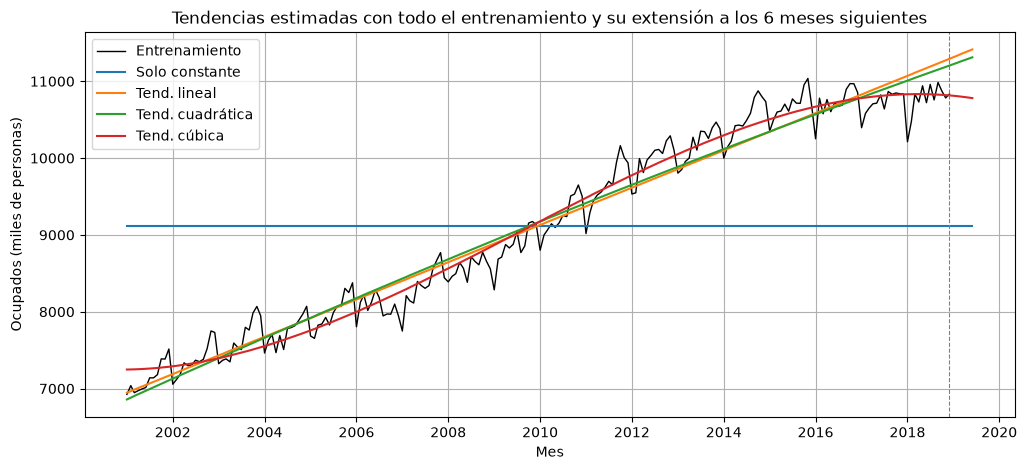


Coeficientes estimados con todo el entrenamiento (t en años):
                     R²     const      t^1     t^2    t^3
Solo constante   -0.000  9119.366      NaN     NaN    NaN
Tend. lineal      0.962  6945.834  242.627     NaN    NaN
Tend. cuadrática  0.963  6858.193  272.114  -1.646    NaN
Tend. cúbica      0.977  7247.538    8.277  35.254 -1.373

RMSE por corte (miles):
                   Tend. lineal  Tend. cuadrática  Tend. cúbica
inicio_validacion                                              
2016-01                   273.9             519.0         443.0
2016-07                   137.9             324.4         165.3
2017-01                   424.8             598.0         383.8
2017-07                   334.8             433.5         131.3
2018-01                   613.4             653.7         345.1
2018-07                   434.0             394.0         104.3

Pendiente estimada al final de cada periodo de ajuste (miles de personas por año):
                   Tend. l

In [15]:
# Tiempo de referencia: t = 0 en el primer mes de la serie (enero de 2001)
inicio_serie = ocupados.index[0]

# Grado del polinomio de tiempo de cada tendencia
GRADOS_TENDENCIA = {"ninguna": 0, "lineal": 1, "cuadratica": 2, "cubica": 3, "grado_4": 4, "grado_5": 5}


def tiempo_en_anios(fechas):
    """Tiempo transcurrido desde enero de 2001, en años (t = 0 en enero de 2001, t = 1/12 en febrero...)."""
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    return np.asarray(meses_desde_inicio, dtype=float) / 12


def construir_regresores(fechas, tendencia, estacionalidad="ninguna", K=None):
    """Construye la matriz de regresores para las fechas indicadas.

    tendencia: una de las claves de GRADOS_TENDENCIA (polinomio en t, medido en años).
    estacionalidad: "ninguna", "dummies" (11 dummies de mes, con enero como categoría base)
                    o "fourier" (K pares seno-coseno con periodo de 12 meses).
    """
    t = tiempo_en_anios(fechas)
    mes = np.asarray(fechas.month)

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    for potencia in range(1, GRADOS_TENDENCIA[tendencia] + 1):
        X[f"t^{potencia}"] = t ** potencia

    if estacionalidad == "dummies":
        # Las 11 dummies se crean de forma explícita: con pd.get_dummies, un horizonte de
        # 6 meses no tendría todos los meses y las columnas no coincidirían con las del ajuste.
        for numero_mes in range(2, 13):
            X[f"mes_{numero_mes}"] = (mes == numero_mes).astype(float)
    elif estacionalidad == "fourier":
        for k in range(1, K + 1):
            angulo = 2 * np.pi * k * mes / 12
            if 2 * k < 12:  # con k = 6 el seno vale 0 en todos los meses, por eso se omite
                X[f"sen_{k}"] = np.sin(angulo)
            X[f"cos_{k}"] = np.cos(angulo)
    return X


def fechas_siguientes(serie_ajuste, h):
    """Devuelve las h fechas mensuales posteriores al último mes de serie_ajuste."""
    return pd.date_range(serie_ajuste.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS")


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada.

    config["tendencia"] es obligatoria; las demás claves son opcionales:
    - "estacionalidad" ("ninguna", "dummies" o "fourier") y "K" (pares de Fourier).
    - "ventana": número de meses de la ventana móvil; si no se indica, se usa toda la historia (ventana recursiva).
    - "escala": "log" para ajustar el logaritmo de la serie; si no se indica, se usa la escala original.
    """
    ventana = config.get("ventana")
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    y = np.log(serie_ajuste) if config.get("escala") == "log" else serie_ajuste
    X = construir_regresores(serie_ajuste.index, config["tendencia"],
                             config.get("estacionalidad", "ninguna"), config.get("K"))
    return sm.OLS(y, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes, en miles de personas."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"],
                                    config.get("estacionalidad", "ninguna"), config.get("K"))
    pronostico = np.asarray(ajuste.predict(X_futuro))
    # En escala logarítmica, la exponencial devuelve el pronóstico a miles de personas
    return np.exp(pronostico) if config.get("escala") == "log" else pronostico


def evaluar_regresion(nombre, config):
    """Evalúa una configuración de regresión en la validación y guarda el resultado en validacion."""
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h: pronostico_regresion(serie_ajuste, h, config)
    )


def pendiente_final(ajuste, t_final):
    """Pendiente de la tendencia polinómica en t_final (derivada del polinomio), en miles de personas por año."""
    return sum(k * ajuste.params.get(f"t^{k}", 0) * t_final ** (k - 1)
               for k in range(1, max(GRADOS_TENDENCIA.values()) + 1))


# Configuraciones con tendencia y sin estacionalidad, con ventana recursiva
configuraciones_tendencia = {
    "Solo constante":   dict(tendencia="ninguna"),
    "Tend. lineal":     dict(tendencia="lineal"),
    "Tend. cuadrática": dict(tendencia="cuadratica"),
    "Tend. cúbica":     dict(tendencia="cubica"),
}
for nombre, config in configuraciones_tendencia.items():
    evaluar_regresion(nombre, config)

modelos_tendencia = list(configuraciones_tendencia)
print("Resumen de la validación:")
print(resumir_validacion(modelos_referencia + modelos_tendencia).round(2).to_string())

# Coeficientes y R² de cada tendencia estimada con todo el entrenamiento, solo para interpretarlos,
# y gráfica de las curvas estimadas extendidas a los 6 meses siguientes
fechas_grafica = train.index.append(fechas_siguientes(train, horizonte))
coeficientes = {}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, color="black", linewidth=1, label="Entrenamiento")
for nombre, config in configuraciones_tendencia.items():
    ajuste = ajustar_regresion(train, config)
    coeficientes[nombre] = pd.concat([ajuste.params, pd.Series({"R²": ajuste.rsquared})])
    ax.plot(fechas_grafica, ajuste.predict(construir_regresores(fechas_grafica, config["tendencia"])),
            label=nombre)
ax.axvline(train.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Tendencias estimadas con todo el entrenamiento y su extensión a los 6 meses siguientes")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()

print("\nCoeficientes estimados con todo el entrenamiento (t en años):")
print(pd.DataFrame(coeficientes).T.round(3).to_string())

# Error por corte y pendiente de cada tendencia en el último mes de ajuste de cada corte.
# La pendiente es la velocidad de crecimiento que el modelo extiende hacia los 6 meses de validación.
modelos_polinomio = ["Tend. lineal", "Tend. cuadrática", "Tend. cúbica"]
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_polinomio).round(1).to_string())

filas = []
for idx_ajuste, idx_validacion in tscv.split(train):
    serie_ajuste = train.iloc[idx_ajuste]
    t_final = tiempo_en_anios(serie_ajuste.index[-1:])[0]
    fila = {"inicio_validacion": train.index[idx_validacion[0]].strftime("%Y-%m")}
    for nombre in modelos_polinomio:
        fila[nombre] = pendiente_final(ajustar_regresion(serie_ajuste, configuraciones_tendencia[nombre]), t_final)
    filas.append(fila)

print("\nPendiente estimada al final de cada periodo de ajuste (miles de personas por año):")
print(pd.DataFrame(filas).set_index("inicio_validacion").round(1).to_string())

### Resultados de la regresión con tendencia

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional | $R^2$ con todo el entrenamiento |
|---|---|---|---|---|
| Naive estacional | 133.36 | 1.05 | — | — |
| Naive | 192.42 | 1.41 | 1 | — |
| Tendencia cúbica | 262.15 | 2.15 | 1 | 0.977 |
| Tendencia lineal | 369.80 | 3.22 | 0 | 0.962 |
| Tendencia cuadrática | 487.08 | 4.41 | 0 | 0.963 |
| Solo constante | 1806.82 | 16.74 | 0 | 0.000 |

Ningún modelo con solo tendencia supera al naive ni al naive estacional en promedio. Era de esperar, porque estos modelos no incluyen la estacionalidad, que según la sección 4 mueve la serie entre 310 mil personas por debajo de la tendencia en enero y 201 mil por encima en noviembre. El modelo con solo la constante pronostica el promedio de toda la historia, cerca de 9,100 mil, muy por debajo del nivel de 2016-2018, y tiene un error de más de 1.8 millones de personas.

La comparación entre tendencias muestra que el $R^2$ no ordena los modelos como la validación. La tendencia cuadrática tiene un $R^2$ apenas mayor que la lineal, pero un error de validación cerca de 32 % mayor. La razón aparece al calcular la pendiente de cada tendencia en el último mes de ajuste de cada corte, que es la velocidad de crecimiento que el modelo extiende hacia los meses de validación:

| Inicio del corte | Lineal | Cuadrática | Cúbica |
|---|---|---|---|
| 2016-01 | 263.3 | 362.2 | 309.2 |
| 2016-07 | 260.7 | 335.2 | 221.3 |
| 2017-01 | 259.6 | 320.2 | 182.1 |
| 2017-07 | 255.2 | 288.4 | 96.6 |
| 2018-01 | 251.9 | 265.8 | 49.3 |
| 2018-07 | 246.4 | 233.6 | -22.0 |

*Pendiente en miles de personas por año.*

Con los datos hasta 2015, la tendencia cuadrática se curva hacia arriba: interpreta que el crecimiento se está acelerando y pronostica para 2016 un aumento de 362 mil personas por año, cuando la serie en realidad se estancó. A medida que el ajuste incluye más años sin crecimiento, su pendiente baja, y solo en el último corte queda por debajo de la lineal y obtiene un menor error (394.0 frente a 434.0 mil). La tendencia lineal, en cambio, mantiene una pendiente casi constante de 246 a 263 mil por año en todos los cortes, porque cada año nuevo pesa poco frente a los 15 a 17 años anteriores.

La tendencia cúbica es la única que se adapta al aplanamiento: su pendiente baja de 309.2 a -22.0 mil por año a lo largo de los cortes, y su error baja de 443.0 a 104.3 mil, de modo que en el último corte supera al naive estacional (104.3 frente a 153.9 mil). Sin embargo, la adaptación es lenta, porque el polinomio se estima con toda la historia, y en el último corte la pendiente ya es negativa, mientras que según la descomposición de la sección 4 la tendencia real creció cerca de 17 mil personas por año entre 2016 y 2018. En la gráfica, la curva cúbica empieza a descender al final del entrenamiento, lo que muestra el riesgo de extender un polinomio de grado alto fuera de la muestra.

Estos resultados dejan dos conclusiones para las siguientes secciones. Primero, la tendencia por sí sola no basta y es necesario agregar la estacionalidad. Segundo, un polinomio estimado con toda la historia reacciona tarde al cambio de pendiente de 2016, por lo que más adelante se evalúa estimar los coeficientes solo con los años más recientes.

## 9. Regresión con tendencia y estacionalidad (variables dummy)

La estacionalidad se incorpora con una variable dummy por mes, que vale 1 si la observación corresponde a ese mes y 0 en otro caso:

$$y_t = \beta_0 + f(t) + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

donde $f(t)$ es la tendencia polinómica de la sección anterior y $D_{j,t}$ es la dummy del mes $j$. Enero es la categoría base: su efecto queda incluido en la constante $\beta_0$, y cada coeficiente $\delta_j$ mide cuánto difiere el mes $j$ de enero con la misma tendencia. Se usan 11 dummies y no 12 porque, junto con la constante, la doceava sería una combinación lineal exacta de las demás (las 12 siempre suman 1), y MCO no podría estimar los coeficientes.

Con las dummies, cada mes tiene su propio efecto, sin imponer una forma al patrón estacional, lo que permite representar el cambio brusco entre diciembre y enero observado en la sección 4. Se combinan con las cuatro tendencias de la sección anterior, con ventana recursiva y en la escala original de la serie, es decir, con estacionalidad aditiva.

In [16]:
# Tendencias de la sección anterior combinadas con las 11 dummies de mes (ventana recursiva)
configuraciones_dummies = {
    "Sin tend. + dummies":        dict(tendencia="ninguna",    estacionalidad="dummies"),
    "Tend. lineal + dummies":     dict(tendencia="lineal",     estacionalidad="dummies"),
    "Tend. cuadrática + dummies": dict(tendencia="cuadratica", estacionalidad="dummies"),
    "Tend. cúbica + dummies":     dict(tendencia="cubica",     estacionalidad="dummies"),
}
for nombre, config in configuraciones_dummies.items():
    evaluar_regresion(nombre, config)

modelos_dummies = list(configuraciones_dummies)
print("Resumen de la validación:")
print(resumir_validacion(modelos_referencia + modelos_tendencia + modelos_dummies).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional"] + modelos_dummies).round(1).to_string())

Resumen de la validación:
                            RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Naive estacional                   133.36               1.05                                    0
Naive                              192.42               1.41                                    1
Tend. cúbica + dummies             222.08               1.91                                    1
Tend. cúbica                       262.15               2.15                                    1
Tend. lineal + dummies             361.44               3.24                                    0
Tend. lineal                       369.80               3.22                                    0
Tend. cuadrática                   487.08               4.41                                    0
Tend. cuadrática + dummies         491.77               4.47                                    0
Solo constante                    1806.82              16.74                                

### Resultados de la regresión con tendencia y dummies

| Tendencia | RMSE sin dummies (miles) | RMSE con dummies (miles) | MAPE con dummies (%) | Cortes en que supera al naive estacional |
|---|---|---|---|---|
| Cúbica | 262.15 | 222.08 | 1.91 | 1 |
| Lineal | 369.80 | 361.44 | 3.24 | 0 |
| Cuadrática | 487.08 | 491.77 | 4.47 | 0 |
| Ninguna | 1806.82 | 1829.96 | 17.01 | 0 |

Agregar las dummies de mes casi no cambia el error: el RMSE baja cerca de 15 % con la tendencia cúbica y 2 % con la lineal, y sube levemente con la cuadrática. Ningún modelo supera al naive estacional en promedio (133.36 mil), y solo el modelo con tendencia cúbica lo supera en un corte, el de julio de 2018.

La razón es que el error de estos modelos proviene principalmente de la tendencia y no de la estacionalidad. Las dummies corrigen el patrón de los meses, que según la sección 4 mueve la serie entre 310 mil personas por debajo de la tendencia y 201 mil por encima, pero no corrigen el nivel. Con la tendencia lineal, el error por corte crece de 174.7 mil en el primer semestre de 2016 a 543.9 mil en el segundo de 2018, porque el modelo sigue pronosticando un crecimiento de cerca de 250 mil personas por año sobre una serie que se estancó, y la diferencia se acumula. Con la tendencia cúbica ocurre lo contrario: el error baja de 297.3 a 128.5 mil a medida que su pendiente se adapta al aplanamiento, como se vio en la sección anterior.

El modelo sin tendencia y con dummies empeora frente al que solo tiene la constante. Sin un término de tendencia, cada coeficiente de mes recoge, además del efecto estacional, el crecimiento promedio de la serie entre enero y ese mes. Por ejemplo, como la serie creció cerca de 20 mil personas por mes durante la mayor parte del periodo, el efecto de diciembre frente a enero queda sobreestimado en cerca de 220 mil personas por la sola tendencia.

Por lo tanto, la estacionalidad solo mejora el pronóstico si la tendencia está bien especificada. La tendencia cúbica es la mejor con y sin estacionalidad, y es el grado más alto evaluado hasta ahora. Para verificar que la búsqueda no quedó corta en ese borde, a continuación se evalúan tendencias de grado 4 y 5 con dummies.

In [17]:
# Revisión del borde de la búsqueda: tendencias de grado 4 y 5 con dummies (ventana recursiva)
configuraciones_grado_alto = {
    "Tend. grado 4 + dummies": dict(tendencia="grado_4", estacionalidad="dummies"),
    "Tend. grado 5 + dummies": dict(tendencia="grado_5", estacionalidad="dummies"),
}
for nombre, config in configuraciones_grado_alto.items():
    evaluar_regresion(nombre, config)

# Comparación de todos los grados con dummies
modelos_grado = ["Tend. lineal + dummies", "Tend. cuadrática + dummies", "Tend. cúbica + dummies",
                 "Tend. grado 4 + dummies", "Tend. grado 5 + dummies"]
print("Validación por grado de la tendencia (con dummies):")
print(resumir_validacion(modelos_grado).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_grado).round(1).to_string())

# Pendiente de la tendencia en el último mes de ajuste de cada corte, para los tres grados más altos
configuraciones_con_dummies = {**configuraciones_dummies, **configuraciones_grado_alto}
filas = []
for idx_ajuste, idx_validacion in tscv.split(train):
    serie_ajuste = train.iloc[idx_ajuste]
    t_final = tiempo_en_anios(serie_ajuste.index[-1:])[0]
    fila = {"inicio_validacion": train.index[idx_validacion[0]].strftime("%Y-%m")}
    for nombre in modelos_grado[2:]:
        fila[nombre] = pendiente_final(ajustar_regresion(serie_ajuste, configuraciones_con_dummies[nombre]), t_final)
    filas.append(fila)

print("\nPendiente estimada al final de cada periodo de ajuste (miles de personas por año):")
print(pd.DataFrame(filas).set_index("inicio_validacion").round(1).to_string())

Validación por grado de la tendencia (con dummies):
                            RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Tend. grado 5 + dummies            129.50               1.04                                    4
Tend. grado 4 + dummies            193.53               1.58                                    1
Tend. cúbica + dummies             222.08               1.91                                    1
Tend. lineal + dummies             361.44               3.24                                    0
Tend. cuadrática + dummies         491.77               4.47                                    0

RMSE por corte (miles):
                   Tend. lineal + dummies  Tend. cuadrática + dummies  Tend. cúbica + dummies  Tend. grado 4 + dummies  Tend. grado 5 + dummies
inicio_validacion                                                                                                                              
2016-01                             174.7      

### Revisión de tendencias de mayor grado

| Tendencia (con dummies) | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Cúbica | 222.08 | 1.91 | 1 |
| Grado 4 | 193.53 | 1.58 | 1 |
| Grado 5 | 129.50 | 1.04 | 4 |

Cada grado adicional reduce el error, y con grado 5 el modelo obtiene un RMSE promedio menor que el del naive estacional (133.36 mil) y lo supera en 4 de los 6 cortes. Sin embargo, la pendiente estimada al final de cada periodo de ajuste muestra que esta mejora no proviene de representar mejor la tendencia. Desde el segundo corte, las tendencias de grado 4 y 5 tienen pendientes negativas, de hasta -295.2 y -139.0 mil personas por año, es decir, pronostican una caída del número de ocupados, mientras que según la descomposición de la sección 4 la serie creció cerca de 17 mil personas por año entre 2016 y 2018.

Estos modelos reducen el error porque un polinomio de grado alto se curva para seguir de cerca los últimos años del ajuste, de modo que el pronóstico parte de un nivel cercano al de las observaciones más recientes, y en un horizonte de 6 meses una pendiente equivocada acumula poco error: con -139 mil personas por año, la diferencia en medio año es de cerca de 70 mil. La ganancia proviene de aproximar el nivel reciente de la serie, no de modelar su tendencia. Además, la forma en que el polinomio se curva al final de la muestra cambia de un corte a otro: la pendiente de grado 5 pasa de +51.4 a -139.0 mil personas por año, y en los cortes de 2018 los grados 4 y 5 tienen errores mayores que la cúbica (309.5 y 214.7 frente a 189.7 mil en enero de 2018). Como el error sigue bajando con cada grado, aumentar el grado no tiene un punto de parada natural y llevaría a ajustar la curva a las últimas observaciones de cada corte.

El problema de fondo es que una tendencia polinómica estimada con toda la historia da el mismo peso a los años de crecimiento que a los años recientes, y no puede representar el cambio de pendiente de 2016 sin curvarse de forma poco realista. En lugar de seguir aumentando el grado, en la siguiente sección se estima la tendencia solo con los años más recientes, que busca el mismo efecto de seguir el nivel actual de la serie, pero de forma directa y con tendencias de bajo grado. Los modelos de grado 4 y 5 se mantienen en la comparación, teniendo en cuenta que sus pronósticos implican una caída de la serie que los datos no muestran.

## 10. Ventana móvil frente a ventana recursiva

Hasta ahora, en cada corte los coeficientes se estimaron con todos los meses disponibles desde enero de 2001 (ventana recursiva o expansiva). Con una **ventana móvil**, en cambio, se usan solo los últimos $w$ meses antes del corte, de modo que la estimación olvida la historia más antigua.

A diferencia de la suavización exponencial, en la que los parámetros de suavización ya dan más peso a la información reciente, la regresión estima coeficientes fijos para todo el periodo de ajuste: la pendiente y los efectos de cada mes son un promedio de toda la historia usada. Por eso, en la regresión el periodo de estimación es la forma directa de adaptar el modelo al cambio de pendiente de 2016, y se evalúa como una dimensión más de la búsqueda. La ventaja esperada es que la pendiente se estime con los años en que la serie ya se había estancado, en lugar de promediarla con el crecimiento de 2001 a 2015. La desventaja es que con menos datos los coeficientes se estiman con más incertidumbre, en particular los efectos de cada mes, que con una ventana de 24 meses se estiman con solo 2 observaciones por mes.

Se usan las mismas ventanas que en el análisis de sensibilidad de la suavización exponencial, de 24, 36, 48, 60 y 96 meses, con tendencias de grado bajo (ninguna, lineal y cuadrática) y estacionalidad con dummies. No se usan grados mayores, porque con una ventana corta el polinomio no necesita curvarse para seguir un cambio de pendiente, y un grado alto con pocos datos aumentaría el riesgo de extrapolar de forma inestable. La ventana recursiva de las secciones anteriores sirve como referencia, porque equivale a una ventana que incluye toda la historia.

In [18]:
# Tendencias de grado bajo con dummies, estimadas con cada ventana móvil
modelos_base_ventana = ["Sin tend. + dummies", "Tend. lineal + dummies", "Tend. cuadrática + dummies"]

modelos_regresion_ventana = []
for w in ventanas_estimacion:
    for nombre_base in modelos_base_ventana:
        nombre = f"{nombre_base}, ventana {w}"
        evaluar_regresion(nombre, {**configuraciones_dummies[nombre_base], "ventana": w})
        modelos_regresion_ventana.append(nombre)

print("RMSE promedio de validación (miles), por tendencia y ventana (meses):")
print(tabla_por_ventana(modelos_base_ventana).round(2).to_string())
print("\nMAPE promedio de validación (%), por tendencia y ventana (meses):")
print(tabla_por_ventana(modelos_base_ventana, metrica="mape").round(2).to_string())

# Los 5 mejores modelos con ventana móvil y su error por corte
resumen_regresion_ventana = resumir_validacion(modelos_regresion_ventana)
print("\nMejores modelos con ventana móvil:")
print(resumen_regresion_ventana.head(5).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional"] + list(resumen_regresion_ventana.index[:5])).round(1).to_string())

RMSE promedio de validación (miles), por tendencia y ventana (meses):
                                24      36      48      60      96  Recursiva
Sin tend. + dummies         141.78  195.78  270.02  367.71  779.37    1829.96
Tend. lineal + dummies      123.68  157.16  196.39  229.49  397.28     361.44
Tend. cuadrática + dummies  142.64  137.44  148.14  143.58  142.89     491.77

MAPE promedio de validación (%), por tendencia y ventana (meses):
                              24    36    48    60    96  Recursiva
Sin tend. + dummies         1.09  1.62  2.28  3.24  7.18      17.01
Tend. lineal + dummies      0.94  1.29  1.70  1.98  3.56       3.24
Tend. cuadrática + dummies  1.10  1.09  1.13  1.16  1.17       4.47

Mejores modelos con ventana móvil:
                                        RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Tend. lineal + dummies, ventana 24             123.68               0.94                                    3
Tend. cuadrática + dumm

### Resultados de la ventana móvil

RMSE promedio de validación (miles) por tendencia y tamaño de la ventana:

| Tendencia (con dummies) | 24 meses | 36 meses | 48 meses | 60 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|---|
| Sin tendencia | 141.78 | 195.78 | 270.02 | 367.71 | 779.37 | 1829.96 |
| Lineal | **123.68** | 157.16 | 196.39 | 229.49 | 397.28 | 361.44 |
| Cuadrática | 142.64 | 137.44 | 148.14 | 143.58 | 142.89 | 491.77 |

Estimar los coeficientes solo con los años recientes reduce el error de forma importante. Con la tendencia lineal, el RMSE baja de 361.44 mil con la ventana recursiva a 123.68 mil con una ventana de 24 meses, cerca de 66 % menos, porque la pendiente se estima con los dos últimos años, cuando la serie ya se había estancado, y no con el crecimiento de 2001 a 2015. A diferencia de lo observado en la suavización exponencial, el efecto de la ventana es grande y sigue un orden claro: con la tendencia lineal y con el modelo sin tendencia, el error baja de forma continua a medida que la ventana se acorta. El modelo sin tendencia mejora porque su constante pasa a ser el nivel promedio de los años recientes y no el de toda la historia. La tendencia cuadrática, en cambio, tiene un error parecido con cualquier ventana, entre 137.44 y 148.14 mil, porque su curvatura le permite seguir el aplanamiento incluso con 8 años de datos, pero ninguna de sus versiones alcanza a la lineal con 24 meses.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Tendencia lineal + dummies, ventana de 24 meses | 123.68 | 0.94 | 3 |
| Tendencia cuadrática + dummies, ventana de 36 meses | 137.44 | 1.09 | 2 |
| Sin tendencia + dummies, ventana de 24 meses | 141.78 | 1.09 | 3 |
| Naive estacional | 133.36 | 1.05 | — |

La tendencia lineal con dummies y una ventana de 24 meses es el primer modelo de regresión con una tendencia de grado bajo que supera al naive estacional en las dos métricas: reduce el RMSE promedio en cerca de 7.3 % y el MAPE de 1.05 % a 0.94 %. Supera al naive estacional en 3 de los 6 cortes, con las mayores diferencias en julio de 2016 y enero de 2017 (57.5 y 65.9 mil frente a 113.5 y 122.8 mil). Pierde en enero de 2016, cuando su ventana de ajuste corresponde a 2014 y 2015, años en que la serie todavía crecía, y el modelo extiende ese crecimiento al primer año sin aumento; y en enero de 2018, el corte con la mayor caída de enero del entrenamiento (532 mil personas frente a la tendencia, según la sección 4), que es difícil para todos los modelos.

La mejor ventana es la más corta evaluada. No se evalúan ventanas menores a 24 meses porque, con menos de dos años completos, algunos meses tendrían una sola observación en el ajuste, y su efecto estimado sería exactamente ese valor, sin promediar entre años. Además, con 24 meses el modelo ya estima 13 coeficientes (la constante, la pendiente y 11 dummies) con 24 observaciones. Por eso, en la siguiente sección se evalúa una forma de representar la estacionalidad con menos coeficientes.

## 11. Estacionalidad con términos de Fourier

En lugar de 11 dummies, la estacionalidad se puede representar con $K$ pares de funciones seno y coseno con periodo de 12 meses:

$$s_t = \sum_{k=1}^{K} \left[ a_k \sin\left(\frac{2\pi k\, m_t}{12}\right) + b_k \cos\left(\frac{2\pi k\, m_t}{12}\right) \right]$$

donde $m_t$ es el número del mes (1 a 12). Cada par agrega una onda que se repite $k$ veces por año: con $K = 1$ el patrón estacional es una sola onda suave, y cada término adicional permite representar cambios más bruscos entre meses. Con $K = 6$ se obtienen 11 regresores, porque el seno de frecuencia 6 vale cero en todos los meses, y el modelo es equivalente al de 11 dummies.

La ventaja de los términos de Fourier es que con un $K$ pequeño la estacionalidad se estima con menos coeficientes, lo que reduce la incertidumbre de las estimaciones cuando la ventana tiene pocos datos. La desventaja es que un patrón suave puede no representar bien la caída brusca de enero observada en la sección 4. Para que la comparación con las dummies sea equivalente, se evalúan $K$ de 1 a 6 con las mismas tendencias (sin tendencia, lineal y cuadrática) y las mismas ventanas de la sección anterior (24, 36, 48, 60 y 96 meses, y la ventana recursiva). Como verificación, el modelo con $K = 6$ debe obtener exactamente el mismo error que el modelo con dummies en cada combinación.

In [19]:
# Misma grilla de tendencias y ventanas que con dummies (None = ventana recursiva)
tendencias_fourier = {"Sin tend.": "ninguna", "Tend. lineal": "lineal", "Tend. cuadrática": "cuadratica"}
valores_K = range(1, 7)
ventanas_con_recursiva = ventanas_estimacion + [None]


def nombre_con_ventana(nombre_base, ventana):
    """Nombre con que se guarda un modelo en validacion: el nombre base si la ventana es recursiva."""
    return nombre_base if ventana is None else f"{nombre_base}, ventana {ventana}"


modelos_fourier = []
for etiqueta, tendencia in tendencias_fourier.items():
    for K in valores_K:
        for w in ventanas_con_recursiva:
            nombre = nombre_con_ventana(f"{etiqueta} + Fourier K={K}", w)
            evaluar_regresion(nombre, dict(tendencia=tendencia, estacionalidad="fourier", K=K, ventana=w))
            modelos_fourier.append(nombre)

# Verificación: con K = 6 el modelo es equivalente al de 11 dummies en cada tendencia y ventana
for etiqueta in tendencias_fourier:
    for w in ventanas_con_recursiva:
        rmse_fourier_6 = validacion[nombre_con_ventana(f"{etiqueta} + Fourier K=6", w)]["rmse"]
        rmse_dummies = validacion[nombre_con_ventana(f"{etiqueta} + dummies", w)]["rmse"]
        assert np.allclose(rmse_fourier_6, rmse_dummies), f"{etiqueta}, ventana {w}: K=6 no coincide con dummies"
print("Verificación: con K = 6 el error coincide con el de las dummies en todas las configuraciones.\n")

# Tablas de RMSE y MAPE promedio por K (filas) y ventana (columnas), una por tendencia
for etiqueta in tendencias_fourier:
    nombres_base = [f"{etiqueta} + Fourier K={K}" for K in valores_K]
    for metrica, titulo in [("rmse", "RMSE promedio (miles)"), ("mape", "MAPE promedio (%)")]:
        tabla = tabla_por_ventana(nombres_base, metrica=metrica)
        tabla.index = [f"K={K}" for K in valores_K]
        print(f"{etiqueta}: {titulo} por K y ventana (meses)")
        print(tabla.round(2).to_string())
        print()

# Los 5 mejores modelos con Fourier y su error por corte
resumen_fourier = resumir_validacion(modelos_fourier)
print("Mejores modelos con términos de Fourier:")
print(resumen_fourier.head(5).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional"] + list(resumen_fourier.index[:5])).round(1).to_string())

Verificación: con K = 6 el error coincide con el de las dummies en todas las configuraciones.

Sin tend.: RMSE promedio (miles) por K y ventana (meses)
         24      36      48      60      96  Recursiva
K=1  165.31  211.61  282.80  377.82  779.17    1830.07
K=2  149.17  201.80  274.04  369.88  774.52    1828.12
K=3  151.09  204.51  275.76  372.11  779.89    1830.30
K=4  143.89  198.41  271.65  369.19  778.11    1829.56
K=5  141.97  196.24  269.64  367.56  779.55    1830.13
K=6  141.78  195.78  270.02  367.71  779.37    1829.96

Sin tend.: MAPE promedio (%) por K y ventana (meses)
       24    36    48    60    96  Recursiva
K=1  1.35  1.76  2.38  3.28  7.07      16.96
K=2  1.14  1.60  2.32  3.23  7.08      16.96
K=3  1.15  1.68  2.35  3.27  7.14      16.99
K=4  1.06  1.63  2.32  3.26  7.14      16.99
K=5  1.06  1.64  2.29  3.25  7.18      17.01
K=6  1.09  1.62  2.28  3.24  7.18      17.01

Tend. lineal: RMSE promedio (miles) por K y ventana (meses)
         24      36      48      

### Resultados de los términos de Fourier

La verificación confirma que con $K = 6$ el error coincide con el de las dummies en las 18 combinaciones de tendencia y ventana. RMSE promedio de validación (miles) de la tendencia lineal, que tiene los menores errores:

| $K$ | 24 meses | 36 meses | 48 meses | 60 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|---|
| 1 | 163.56 | 185.53 | 218.14 | 252.11 | 412.32 | 374.86 |
| 2 | 138.31 | 169.07 | 205.13 | 238.66 | 403.01 | 367.64 |
| 3 | 135.00 | 167.48 | 202.12 | 235.85 | 401.99 | 366.31 |
| 4 | 129.66 | 162.59 | 199.38 | 233.48 | 400.12 | 364.66 |
| 5 | 124.33 | 157.18 | 194.75 | 229.21 | 397.58 | 362.18 |
| 6 (= dummies) | **123.68** | 157.16 | 196.39 | 229.49 | 397.28 | 361.44 |

Reducir el número de términos de Fourier no mejora el pronóstico. Con la tendencia lineal y la ventana de 24 meses, el RMSE baja de forma casi continua al aumentar $K$, de 163.56 mil con una sola onda a 123.68 mil con $K = 6$, y el mismo comportamiento se repite con las demás tendencias y ventanas: el menor error se obtiene con $K = 5$ o $K = 6$ en todas las combinaciones salvo dos, el modelo sin tendencia con la ventana de 96 meses y con la ventana recursiva, en las que $K = 2$ tiene un error apenas menor y que superan los 770 mil personas. En todos los casos, las mejoras frente a las dummies son menores a 1 %. La razón es la forma del patrón estacional observada en la sección 4: el cambio de +98 a -310 mil personas entre diciembre y enero solo se puede representar con ondas de frecuencia alta, de modo que un patrón suave pierde más precisión de la que gana al estimar menos coeficientes. Las conclusiones sobre la tendencia y la ventana no cambian: la ventana recursiva sigue teniendo errores mayores a 360 mil con cualquier $K$.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| Tendencia lineal + dummies, ventana de 24 meses | 123.68 | 0.94 | 3 |
| Tendencia lineal + Fourier $K = 5$, ventana de 24 meses | 124.33 | 0.97 | 4 |
| Naive estacional | 133.36 | 1.05 | — |

El modelo con $K = 5$ obtiene un error prácticamente igual al de las dummies (0.5 % mayor) y supera al naive estacional en un corte más, porque su patrón algo más suave reduce el error en los cortes de 2018 (145.7 y 139.3 mil frente a 176.0 y 148.9 mil), aunque lo aumenta en otros, como julio de 2017 (154.9 frente a 128.9 mil). Como la diferencia entre ambos es mínima, el modelo con dummies se mantiene como el mejor por el criterio de RMSE promedio, y además es más fácil de interpretar, porque cada coeficiente corresponde al efecto de un mes.

## 12. Estacionalidad multiplicativa: regresión sobre el logaritmo de la serie

En la sección 4, la descomposición mostró que la caída de enero creció con el nivel de la serie, lo que sugiere una estacionalidad multiplicativa. En una regresión, este supuesto se incorpora ajustando el logaritmo de la serie:

$$\log y_t = \beta_0 + f(t) + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

En esta escala, cada coeficiente se interpreta en términos relativos: $\delta_j$ es aproximadamente el porcentaje en que el mes $j$ se aleja de enero, y la pendiente de una tendencia lineal es aproximadamente la tasa de crecimiento anual. Al volver a la escala original con la exponencial, la tendencia lineal se convierte en un crecimiento exponencial y los efectos de cada mes pasan a ser proporcionales al nivel. El pronóstico en miles de personas se obtiene como $\exp(\widehat{\log y})$, que corresponde a la mediana del pronóstico y no a su media; con errores tan pequeños en escala logarítmica, cercanos a 1 %, la diferencia entre ambas es despreciable.

Para que la comparación con la escala original sea equivalente, se evalúan las mismas tendencias (sin tendencia, lineal y cuadrática) y ventanas (24, 36, 48, 60 y 96 meses, y la recursiva), con estacionalidad por dummies, que fue la mejor representación en la sección anterior.

In [20]:
# Mismas tendencias y ventanas que en la escala original, con dummies y en escala logarítmica
modelos_log = []
for etiqueta, tendencia in tendencias_fourier.items():
    for w in ventanas_con_recursiva:
        nombre = nombre_con_ventana(f"Log: {etiqueta} + dummies", w)
        evaluar_regresion(nombre, dict(tendencia=tendencia, estacionalidad="dummies", ventana=w, escala="log"))
        modelos_log.append(nombre)

# Comparación de RMSE y MAPE promedio: cada tendencia en escala original y logarítmica
filas_comparacion = []
for etiqueta in tendencias_fourier:
    filas_comparacion += [f"{etiqueta} + dummies", f"Log: {etiqueta} + dummies"]

for metrica, titulo in [("rmse", "RMSE promedio (miles)"), ("mape", "MAPE promedio (%)")]:
    print(f"{titulo} con dummies, por escala, tendencia y ventana (meses):")
    print(tabla_por_ventana(filas_comparacion, metrica=metrica).round(2).to_string())
    print()

# Los 5 mejores modelos en escala logarítmica, junto al mejor en escala original, y su error por corte
resumen_log = resumir_validacion(modelos_log)
print("Mejores modelos en escala logarítmica:")
print(resumen_log.head(5).round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional", "Tend. lineal + dummies, ventana 24"]
                      + list(resumen_log.index[:5])).round(1).to_string())

RMSE promedio (miles) con dummies, por escala, tendencia y ventana (meses):
                                     24      36      48      60      96  Recursiva
Sin tend. + dummies              141.78  195.78  270.02  367.71  779.37    1829.96
Log: Sin tend. + dummies         141.94  196.75  272.22  372.04  799.89    1910.11
Tend. lineal + dummies           123.68  157.16  196.39  229.49  397.28     361.44
Log: Tend. lineal + dummies      124.00  159.47  201.97  240.04  452.45     543.96
Tend. cuadrática + dummies       142.64  137.44  148.14  143.58  142.89     491.77
Log: Tend. cuadrática + dummies  144.02  138.21  149.91  143.38  134.27     521.12

MAPE promedio (%) con dummies, por escala, tendencia y ventana (meses):
                                   24    36    48    60    96  Recursiva
Sin tend. + dummies              1.09  1.62  2.28  3.24  7.18      17.01
Log: Sin tend. + dummies         1.09  1.63  2.30  3.28  7.37      17.76
Tend. lineal + dummies           0.94  1.29  1.70  

### Resultados de la escala logarítmica

| Tendencia + dummies | Escala | 24 meses | 36 meses | 96 meses | Recursiva |
|---|---|---|---|---|---|
| Lineal | Original | **123.68** | 157.16 | 397.28 | 361.44 |
| Lineal | Logarítmica | 124.00 | 159.47 | 452.45 | 543.96 |
| Cuadrática | Original | 142.64 | 137.44 | 142.89 | 491.77 |
| Cuadrática | Logarítmica | 144.02 | 138.21 | 134.27 | 521.12 |

*RMSE promedio de validación, en miles de personas.*

Ajustar el logaritmo de la serie no mejora el pronóstico. Con las ventanas cortas, ambas escalas obtienen prácticamente el mismo error: con la tendencia lineal y 24 meses, el RMSE es de 123.68 mil en la escala original y de 124.00 mil en la logarítmica, con el mismo MAPE de 0.94 %. Dentro de una ventana de 24 meses, el nivel de la serie cambia poco, y en un rango tan estrecho un efecto estacional proporcional al nivel y uno fijo en número de personas son casi iguales: por ejemplo, una caída de 3.4 % equivale a 357 mil personas con un nivel de 10,500 mil y a 367 mil con un nivel de 10,800 mil. La evidencia de una estacionalidad multiplicativa de la sección 4 proviene de comparar años con niveles muy distintos, como 2002 y 2018, que nunca quedan dentro de la misma ventana corta.

Con las ventanas largas y la recursiva, la escala logarítmica empeora el error, sobre todo con la tendencia lineal, que pasa de 361.44 a 543.96 mil con la ventana recursiva. Una tendencia lineal sobre el logaritmo equivale a un crecimiento exponencial en la escala original, de modo que, al extenderla fuera de la muestra, el crecimiento de los años anteriores se acumula sobre sí mismo y el pronóstico se aleja aún más de una serie que se había estancado. La única combinación en que el logaritmo reduce el error de forma apreciable es la tendencia cuadrática con 96 meses (134.27 frente a 142.89 mil), pero ese modelo sigue siendo peor que la tendencia lineal con 24 meses y supera al naive estacional en solo 2 de los 6 cortes.

Por lo tanto, la estacionalidad multiplicativa no aporta en la regresión, y se mantiene la escala original, que además permite interpretar los coeficientes directamente en miles de personas.

## 13. Selección del modelo de regresión

En las secciones anteriores se evaluaron, con los mismos 6 cortes de validación, distintas formas de modelar la tendencia (polinomios de grado 0 a 5), la estacionalidad (dummies y términos de Fourier), el periodo de estimación (ventanas de 24 a 96 meses y la ventana recursiva) y la escala de la serie (original y logarítmica). La siguiente tabla resume la mejor configuración de cada etapa, junto con las referencias, y la gráfica compara su RMSE promedio con el del naive estacional. Después se revisa el comportamiento del modelo con menor error en cada corte de validación.

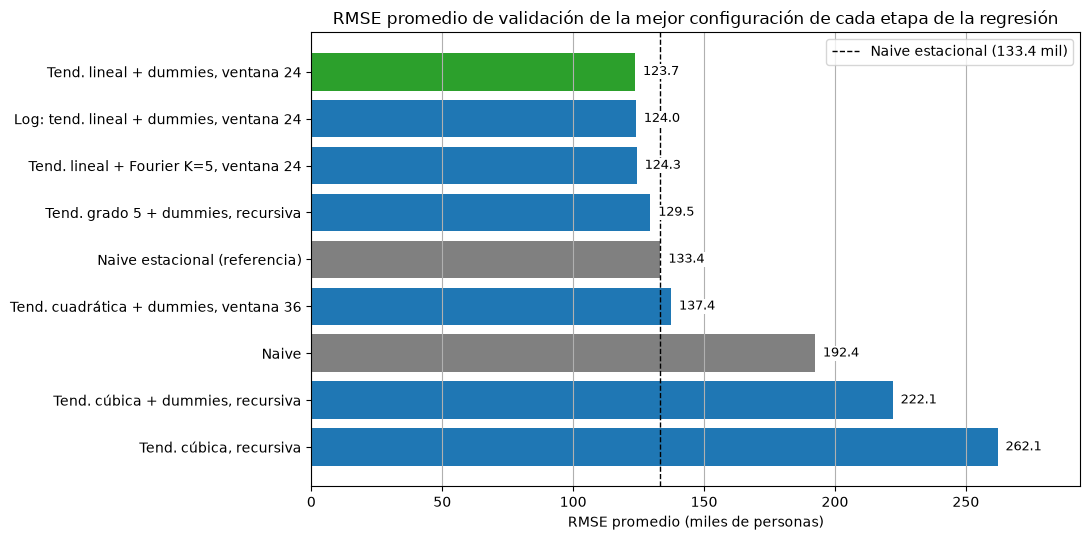

                                         RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Tend. lineal + dummies, ventana 24              123.68               0.94                                    3
Log: tend. lineal + dummies, ventana 24         124.00               0.94                                    3
Tend. lineal + Fourier K=5, ventana 24          124.33               0.97                                    4
Tend. grado 5 + dummies, recursiva              129.50               1.04                                    4
Naive estacional (referencia)                   133.36               1.05                                    0
Tend. cuadrática + dummies, ventana 36          137.44               1.09                                    2
Naive                                           192.42               1.41                                    1
Tend. cúbica + dummies, recursiva               222.08               1.91                                    1
T

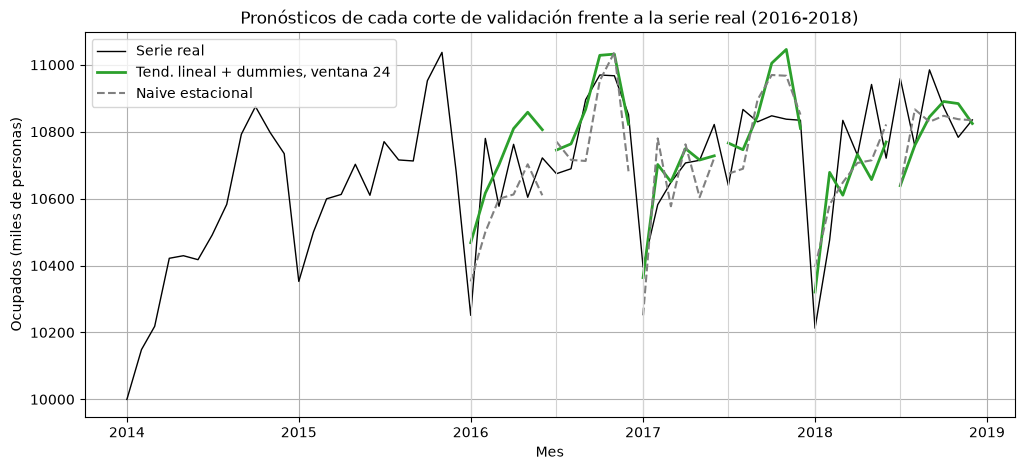


Pendiente estimada en cada corte (miles de personas por año):
2016-01    194.9
2016-07     76.3
2017-01     41.4
2017-07     29.1
2018-01     -1.7
2018-07    -12.2


In [21]:
def graficar_resumen_validacion(modelos, destacado, titulo, referencia="Naive estacional"):
    """Gráfica de barras del RMSE promedio de validación, con la referencia marcada con una línea.

    modelos: diccionario {etiqueta para la gráfica: nombre del modelo en validacion}.
    destacado: etiqueta del modelo que se resalta en verde; las referencias naive van en gris.
    Devuelve la tabla resumen de la validación con las etiquetas como índice.
    """
    etiquetas = {nombre: etiqueta for etiqueta, nombre in modelos.items()}
    resumen = resumir_validacion(list(modelos.values()), referencia=referencia).rename(index=etiquetas)
    rmse_referencia = validacion[referencia]["rmse"].mean()

    orden = resumen.sort_values("RMSE promedio", ascending=False)
    colores = ["C2" if etiqueta == destacado else "gray" if etiqueta.startswith("Naive") else "C0"
               for etiqueta in orden.index]

    fig, ax = plt.subplots(figsize=(11, 0.5 * len(orden) + 1))
    ax.barh(orden.index, orden["RMSE promedio"], color=colores)
    ax.axvline(rmse_referencia, color="black", linestyle="--", linewidth=1,
               label=f"{referencia} ({rmse_referencia:.1f} mil)")
    for posicion, valor in enumerate(orden["RMSE promedio"]):
        # Fondo blanco para que la etiqueta se lea aunque cruce la línea de referencia
        ax.text(valor + 3, posicion, f"{valor:.1f}", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlim(0, orden["RMSE promedio"].max() * 1.12)
    ax.set_title(titulo)
    ax.set_xlabel("RMSE promedio (miles de personas)")
    ax.legend(loc="upper right")
    ax.grid(axis="x")
    plt.tight_layout()
    plt.show()
    return resumen


# Mejor configuración de cada etapa de la regresión, junto con las referencias
nombre_regresion = "Tend. lineal + dummies, ventana 24"
mejores_por_etapa = {
    "Naive": "Naive",
    "Naive estacional (referencia)": "Naive estacional",
    "Tend. cúbica, recursiva": "Tend. cúbica",
    "Tend. cúbica + dummies, recursiva": "Tend. cúbica + dummies",
    "Tend. grado 5 + dummies, recursiva": "Tend. grado 5 + dummies",
    "Tend. cuadrática + dummies, ventana 36": "Tend. cuadrática + dummies, ventana 36",
    "Tend. lineal + Fourier K=5, ventana 24": "Tend. lineal + Fourier K=5, ventana 24",
    "Log: tend. lineal + dummies, ventana 24": "Log: Tend. lineal + dummies, ventana 24",
    "Tend. lineal + dummies, ventana 24": nombre_regresion,
}
resumen_seleccion = graficar_resumen_validacion(
    mejores_por_etapa, destacado="Tend. lineal + dummies, ventana 24",
    titulo="RMSE promedio de validación de la mejor configuración de cada etapa de la regresión",
)
print(resumen_seleccion.round(2).to_string())

# Pronósticos de cada corte de validación del modelo con menor error, frente al naive estacional
config_regresion = dict(tendencia="lineal", estacionalidad="dummies", ventana=24)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.loc["2014":], color="black", linewidth=1, label="Serie real")
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    serie_ajuste = train.iloc[idx_ajuste]
    fechas_validacion = train.index[idx_validacion]
    ax.plot(fechas_validacion, pronostico_regresion(serie_ajuste, len(idx_validacion), config_regresion),
            color="C2", linewidth=2, label=nombre_regresion if numero == 1 else None)
    ax.plot(fechas_validacion, pronostico_naive_estacional(serie_ajuste, len(idx_validacion)),
            color="gray", linestyle="--", label="Naive estacional" if numero == 1 else None)
    ax.axvline(fechas_validacion[0], color="lightgray", linewidth=0.8)
ax.set_title("Pronósticos de cada corte de validación frente a la serie real (2016-2018)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()

# Pendiente estimada en cada corte (coeficiente de t, en miles de personas por año)
pendientes_regresion = pd.Series({
    train.index[idx_validacion[0]].strftime("%Y-%m"):
        ajustar_regresion(train.iloc[idx_ajuste], config_regresion).params["t^1"]
    for idx_ajuste, idx_validacion in tscv.split(train)
}, name="Pendiente (miles por año)")
print("\nPendiente estimada en cada corte (miles de personas por año):")
print(pendientes_regresion.round(1).to_string())

### Elección del modelo de regresión

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| **Tendencia lineal + dummies, ventana de 24 meses** | **123.68** | **0.94** | 3 |
| Logaritmo: tendencia lineal + dummies, ventana de 24 meses | 124.00 | 0.94 | 3 |
| Tendencia lineal + Fourier $K = 5$, ventana de 24 meses | 124.33 | 0.97 | 4 |
| Tendencia de grado 5 + dummies, ventana recursiva | 129.50 | 1.04 | 4 |
| Naive estacional | 133.36 | 1.05 | — |
| Tendencia cuadrática + dummies, ventana de 36 meses | 137.44 | 1.09 | 2 |

El modelo de regresión elegido es el de **tendencia lineal y dummies de mes, estimado con los últimos 24 meses y en la escala original de la serie**:

$$y_t = \beta_0 + \beta_1 t + \sum_{j=2}^{12} \delta_j D_{j,t} + \varepsilon_t$$

Es el modelo con menor RMSE promedio, 7.3 % menor que el del naive estacional, y comparte el menor MAPE con su versión en escala logarítmica. Los dos modelos siguientes, en escala logarítmica y con términos de Fourier, tienen errores menos de 1 % mayores y la misma estructura: una tendencia lineal estimada con los últimos 24 meses. Esto indica que el aspecto decisivo del modelo es la ventana de estimación, y no la escala ni la forma de representar la estacionalidad. Entre ellos se elige la versión en escala original con dummies, que tiene el menor error y es la más fácil de interpretar, porque sus coeficientes están en miles de personas y cada uno corresponde al efecto de un mes. La tendencia de grado 5 tiene un error mayor y, como se vio en la sección 9, pronostica una caída de la serie que los datos no muestran.

La gráfica de los pronósticos por corte muestra que el modelo reproduce el patrón estacional y el nivel de la serie en la mayoría de los semestres. Sus mayores errores aparecen en el primer semestre de 2016, cuando la ventana de ajuste (2014 y 2015) todavía tenía crecimiento y el modelo extendió una pendiente de 194.9 mil personas por año sobre una serie que se había estancado, y en el máximo de octubre y noviembre de 2017, que sobreestima porque los efectos de esos meses se estimaron con 2015 y 2016, años en que el máximo fue más alto. Desde 2017, la pendiente estimada en cada corte está entre -12.2 y 41.4 mil personas por año, coherente con la tendencia casi plana de la serie.

Hay que tener en cuenta que se compararon cerca de 150 configuraciones de regresión con los mismos 6 cortes de validación, por lo que el error de validación del modelo elegido es probablemente algo optimista. Antes de compararlo con los mejores modelos de la Parte I, se evalúan los supuestos de sus residuales.

## 14. Evaluación de los supuestos de los residuales

Los intervalos de predicción de la regresión suponen que los errores del modelo no están autocorrelacionados, tienen varianza constante y siguen una distribución normal. Si los residuales del modelo elegido no cumplen estos supuestos, los pronósticos puntuales pueden seguir siendo útiles, pero los intervalos de predicción no tendrían la cobertura que indican. Se aplican las siguientes pruebas:

- **Autocorrelación:** prueba de rachas, que revisa si los signos de los residuales aparecen en un orden aleatorio, y pruebas de Box-Pierce y Ljung-Box, que revisan si las autocorrelaciones de los residuales son en conjunto distintas de cero.
- **Varianza constante:** prueba de Ljung-Box sobre los residuales al cuadrado y, en los errores de pronóstico, prueba ARCH-LM de Engle, que detectan si la varianza depende de los errores anteriores (comportamiento ARCH o GARCH).
- **Normalidad:** pruebas de Jarque-Bera y Shapiro-Wilk, junto con el histograma y el gráfico Q-Q de los residuales.

En todas, la hipótesis nula corresponde al supuesto que se quiere verificar, y se rechaza con un p-valor menor a 0.05.

Los supuestos se evalúan sobre los residuales del modelo elegido ajustado con los últimos 24 meses del entrenamiento, de enero de 2017 a diciembre de 2018, que es el modelo que se evalúa en la muestra de prueba. Como el modelo estima 13 coeficientes con 24 observaciones, estas pruebas tienen poca potencia: con tan pocos residuales es difícil rechazar la hipótesis nula aunque el supuesto no se cumpla. Por eso, después se complementan con los errores de pronóstico a un mes del mismo modelo a lo largo de toda la serie.

                            OLS Regression Results                            
Dep. Variable:               Ocupados   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     4.225
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0117
Time:                        21:04:37   Log-Likelihood:                -137.71
No. Observations:                  24   AIC:                             301.4
Df Residuals:                      11   BIC:                             316.7
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9773.8225    751.421     13.007      0.0

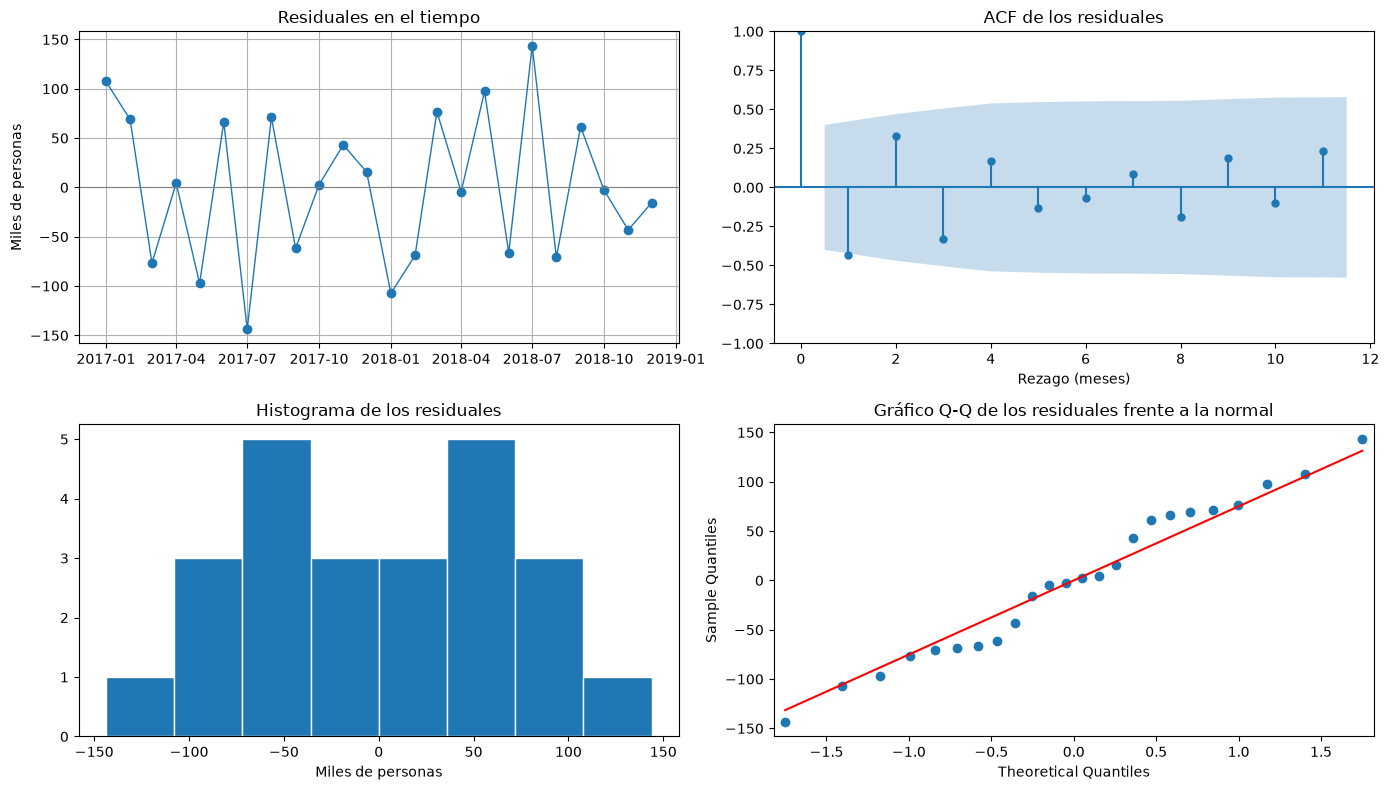

In [22]:
# Modelo de regresión elegido ajustado con los últimos 24 meses del entrenamiento
# (enero de 2017 a diciembre de 2018), que es el modelo que se evalúa en la muestra de prueba
ajuste_regresion = ajustar_regresion(train, config_regresion)
residuos = ajuste_regresion.resid
print(ajuste_regresion.summary())

# Gráficas de diagnóstico de los residuales
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(residuos, marker="o", linewidth=1)
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_title("Residuales en el tiempo")
axes[0, 0].set_ylabel("Miles de personas")
axes[0, 0].grid()

# Con 24 residuales se muestran hasta 11 rezagos (menos de la mitad de la muestra)
plot_acf(residuos, lags=11, ax=axes[0, 1], title="ACF de los residuales")
axes[0, 1].set_xlabel("Rezago (meses)")

axes[1, 0].hist(residuos, bins=8, edgecolor="white")
axes[1, 0].set_title("Histograma de los residuales")
axes[1, 0].set_xlabel("Miles de personas")

# line="s": recta ajustada a los cuantiles de los residuales, que no están estandarizados
sm.qqplot(residuos, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Gráfico Q-Q de los residuales frente a la normal")

fig.tight_layout()
plt.show()

In [23]:
def prueba_ljung_box(serie, rezagos):
    """Pruebas de Box-Pierce y Ljung-Box para cada rezago, con la decisión a un nivel de 0.05.

    H0: las autocorrelaciones hasta cada rezago son cero. Se reporta la decisión de
    ambas pruebas en cada rezago, como en el notebook de clase.
    """
    tabla = acorr_ljungbox(serie, lags=rezagos, boxpierce=True, return_df=True)
    tabla["decision_lb"] = np.where(tabla["lb_pvalue"] < 0.05, "Se rechaza H0", "No se rechaza H0")
    tabla["decision_bp"] = np.where(tabla["bp_pvalue"] < 0.05, "Se rechaza H0", "No se rechaza H0")
    return tabla


# Prueba de rachas. H0: los signos de los residuales aparecen en orden aleatorio.
# cutoff=0 clasifica cada residual según su signo, igual que usar residuos > 0 como en el
# notebook de clase; correction=False, como en ese notebook.
estadistico_rachas, p_rachas = runstest_1samp(residuos, cutoff=0, correction=False)
print(f"Prueba de rachas: estadístico = {estadistico_rachas:.3f}, p-valor = {p_rachas:.3f}")

# Box-Pierce y Ljung-Box en cada rezago. Con 24 residuales se revisan hasta 6 rezagos (cerca de n/4).
rezagos = range(1, 7)
print("\nBox-Pierce y Ljung-Box sobre los residuales:")
print(prueba_ljung_box(residuos, rezagos).round(3).to_string())

# Box-Pierce y Ljung-Box sobre los residuales al cuadrado. H0: no hay autocorrelación en los
# cuadrados, es decir, no hay comportamiento ARCH o GARCH. Los residuales ya tienen media cero.
print("\nBox-Pierce y Ljung-Box sobre los residuales al cuadrado:")
print(prueba_ljung_box(residuos ** 2, rezagos).round(3).to_string())

# Normalidad. H0: los residuales provienen de una distribución normal.
jarque_bera = stats.jarque_bera(residuos)
shapiro_wilk = stats.shapiro(residuos)
print(f"\nJarque-Bera: estadístico = {jarque_bera.statistic:.3f}, p-valor = {jarque_bera.pvalue:.3f}")
print(f"Shapiro-Wilk: estadístico = {shapiro_wilk.statistic:.3f}, p-valor = {shapiro_wilk.pvalue:.3f}")

Prueba de rachas: estadístico = 2.087, p-valor = 0.037

Box-Pierce y Ljung-Box sobre los residuales:
   lb_stat  lb_pvalue  bp_stat  bp_pvalue    decision_lb       decision_bp
1    5.138      0.023    4.546      0.033  Se rechaza H0     Se rechaza H0
2    8.164      0.017    7.105      0.029  Se rechaza H0     Se rechaza H0
3   11.379      0.010    9.702      0.021  Se rechaza H0     Se rechaza H0
4   12.260      0.016   10.380      0.034  Se rechaza H0     Se rechaza H0
5   12.846      0.025   10.809      0.055  Se rechaza H0  No se rechaza H0
6   12.999      0.043   10.914      0.091  Se rechaza H0  No se rechaza H0

Box-Pierce y Ljung-Box sobre los residuales al cuadrado:
   lb_stat  lb_pvalue  bp_stat  bp_pvalue       decision_lb       decision_bp
1    0.098      0.754    0.087      0.768  No se rechaza H0  No se rechaza H0
2    1.207      0.547    1.025      0.599  No se rechaza H0  No se rechaza H0
3    9.845      0.020    8.002      0.046     Se rechaza H0     Se rechaza H0
4   

### Resultados de los supuestos con los residuales de la ventana

| Prueba | Hipótesis nula | Rezagos | p-valor | Resultado |
|---|---|---|---|---|
| Rachas | Signos en orden aleatorio | — | 0.037 | Se rechaza |
| Ljung-Box | Sin autocorrelación | 1 a 6 | 0.010 a 0.043 | Se rechaza en todos |
| Box-Pierce | Sin autocorrelación | 1 a 6 | 0.021 a 0.091 | Se rechaza en 1 a 4, no en 5 y 6 |
| Ljung-Box sobre los cuadrados | Sin comportamiento ARCH | 1 a 6 | 0.004 a 0.754 | Se rechaza en 3 a 6 |
| Box-Pierce sobre los cuadrados | Sin comportamiento ARCH | 1 a 6 | 0.025 a 0.768 | Se rechaza en 3 y 6 |
| Jarque-Bera | Normalidad | — | 0.618 | No se rechaza |
| Shapiro-Wilk | Normalidad | — | 0.664 | No se rechaza |

La prueba de Box-Pierce rechaza en menos rezagos que la de Ljung-Box, porque con muestras pequeñas su estadístico es menor; la de Ljung-Box corrige este sesgo y es la más adecuada con 24 observaciones.

Estos resultados no pueden interpretarse directamente, por una propiedad del modelo con ventana de 24 meses. En la regresión por MCO, los residuales son ortogonales a cada regresor, y como hay una dummy por mes (y la constante para enero), la suma de los residuales de cada mes es cero. Con 24 meses, cada mes tiene solo dos observaciones, de modo que el residual de 2018 es aproximadamente el negativo del de 2017: por ejemplo, 108.0 en enero de 2017 y -107.0 en enero de 2018, y -143.0 en julio de 2017 y 143.0 en julio de 2018. En la gráfica de los residuales en el tiempo, el segundo año repite el primero con el signo invertido.

Esta restricción afecta todas las pruebas. Los 24 residuales tienen en realidad cerca de 11 valores libres, igual que los grados de libertad del modelo. Su distribución es simétrica por construcción, por lo que la asimetría es exactamente 0 y las pruebas de normalidad no la rechazan sin que esto indique que los errores sean normales. Los cuadrados del segundo año repiten los del primero, lo que genera la autocorrelación detectada en los residuales al cuadrado. Y la autocorrelación negativa del rezago 1 ($r_1 \approx -0.43$, con un estadístico de Durbin-Watson de 2.78) no se puede separar del efecto de la restricción. Esto no afecta la evaluación del pronóstico, que se hizo con errores fuera de la muestra de ajuste, pero sí impide usar los residuales de la ventana para verificar los supuestos.

El `summary` también muestra que la pendiente estimada con 2017 y 2018 es de 32.1 mil personas por año, no significativa (p-valor de 0.493), coherente con una serie que no creció en esos años, y que el $R^2$ ajustado es de 0.627, bastante menor que el $R^2$ de 0.822, porque el modelo estima 13 coeficientes con 24 observaciones.

Para evaluar los supuestos sin esta restricción, se usan los errores de pronóstico a un mes del mismo modelo: para cada mes desde enero de 2003 hasta diciembre de 2018, el modelo se ajusta con los 24 meses anteriores y se pronostica el mes siguiente. Así se obtienen 192 errores, cada uno calculado con datos que el modelo no usó para estimar sus coeficientes. Además, con estos pronósticos se puede medir qué porcentaje de los valores reales cae dentro del intervalo de predicción del 95 % del modelo, que es la consecuencia práctica de que los supuestos se cumplan o no.

Errores de pronóstico a un mes: 192 meses, de 2003-01 a 2018-12
Media del error: -3.9 mil | Desviación estándar: 176.0 mil
Cobertura del intervalo de predicción del 95 %: 90.1 %


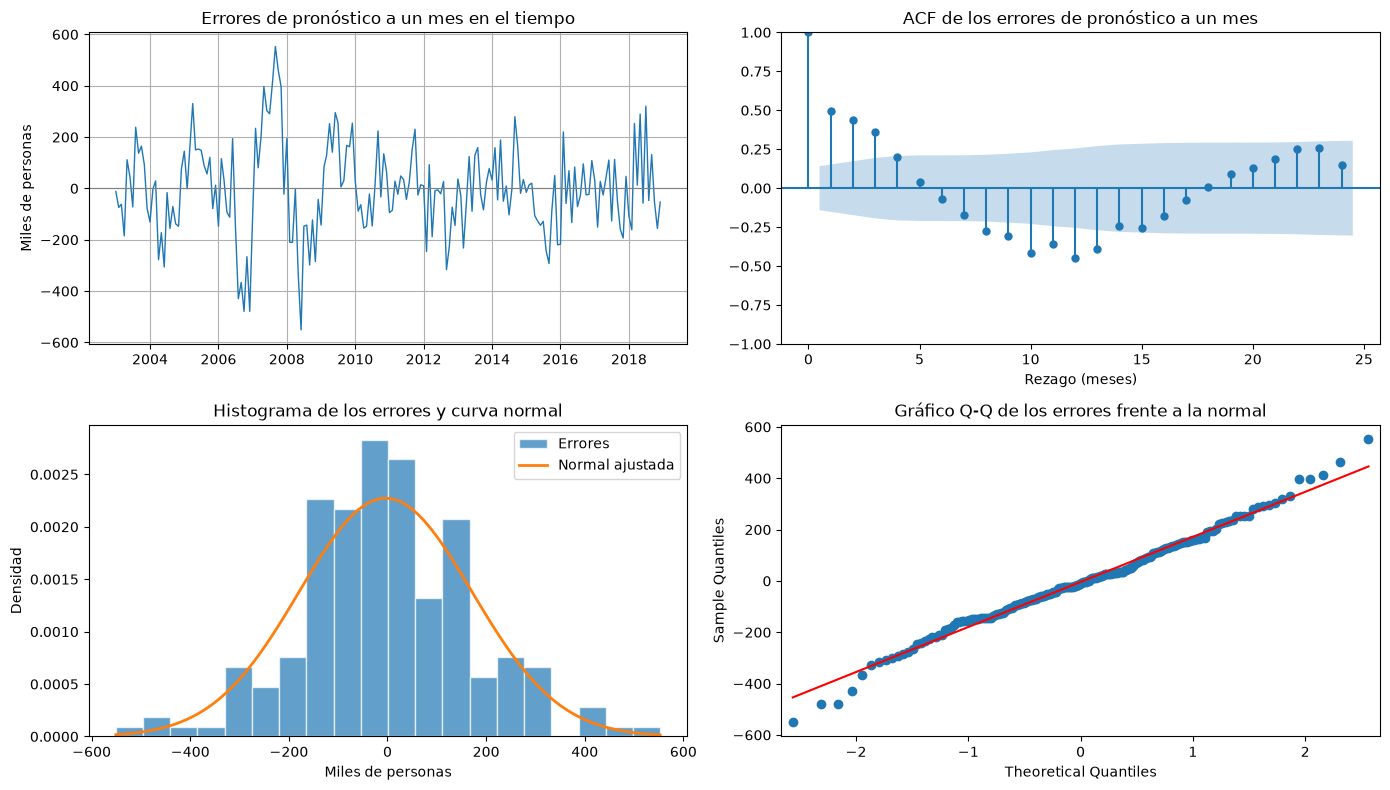


Prueba de rachas: estadístico = -1.980, p-valor = 0.048

Box-Pierce y Ljung-Box sobre los errores:
    lb_stat  lb_pvalue  bp_stat  bp_pvalue    decision_lb    decision_bp
1    48.093        0.0   47.350        0.0  Se rechaza H0  Se rechaza H0
2    85.839        0.0   84.317        0.0  Se rechaza H0  Se rechaza H0
3   111.450        0.0  109.268        0.0  Se rechaza H0  Se rechaza H0
4   119.493        0.0  117.062        0.0  Se rechaza H0  Se rechaza H0
5   119.765        0.0  117.324        0.0  Se rechaza H0  Se rechaza H0
6   120.688        0.0  118.209        0.0  Se rechaza H0  Se rechaza H0
7   126.702        0.0  123.945        0.0  Se rechaza H0  Se rechaza H0
8   142.119        0.0  138.567        0.0  Se rechaza H0  Se rechaza H0
9   161.163        0.0  156.531        0.0  Se rechaza H0  Se rechaza H0
10  197.025        0.0  190.175        0.0  Se rechaza H0  Se rechaza H0
11  223.554        0.0  214.926        0.0  Se rechaza H0  Se rechaza H0
12  265.566        0.0  

In [24]:
# Errores de pronóstico a un mes del modelo de regresión elegido: para cada mes desde enero de 2003,
# el modelo se ajusta con los 24 meses anteriores y pronostica el mes siguiente.
# También se registra si el valor real cae dentro del intervalo de predicción del 95 %.
filas = []
for posicion in range(24, len(train)):
    serie_ajuste = train.iloc[:posicion]
    ajuste = ajustar_regresion(serie_ajuste, config_regresion)   # usa solo los últimos 24 meses
    X_siguiente = construir_regresores(fechas_siguientes(serie_ajuste, 1), config_regresion["tendencia"],
                                       config_regresion["estacionalidad"])
    prediccion = ajuste.get_prediction(X_siguiente).summary_frame(alpha=0.05)
    valor_real = train.iloc[posicion]
    filas.append({
        "mes": train.index[posicion],
        "error": valor_real - prediccion["mean"].iloc[0],
        "dentro_intervalo": prediccion["obs_ci_lower"].iloc[0] <= valor_real <= prediccion["obs_ci_upper"].iloc[0],
    })
errores_un_mes = pd.DataFrame(filas).set_index("mes")
error = errores_un_mes["error"]
print(f"Errores de pronóstico a un mes: {len(error)} meses, de {error.index[0]:%Y-%m} a {error.index[-1]:%Y-%m}")
print(f"Media del error: {error.mean():.1f} mil | Desviación estándar: {error.std():.1f} mil")
print(f"Cobertura del intervalo de predicción del 95 %: {100 * errores_un_mes['dentro_intervalo'].mean():.1f} %")

# Gráficas de diagnóstico de los errores
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(error, linewidth=1)
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_title("Errores de pronóstico a un mes en el tiempo")
axes[0, 0].set_ylabel("Miles de personas")
axes[0, 0].grid()

plot_acf(error, lags=24, ax=axes[0, 1], title="ACF de los errores de pronóstico a un mes")
axes[0, 1].set_xlabel("Rezago (meses)")

# Histograma con la curva normal de igual media y desviación estándar, como en el notebook de clase
media_normal, desviacion_normal = stats.norm.fit(error)
valores_x = np.linspace(error.min(), error.max(), 100)
axes[1, 0].hist(error, bins=20, density=True, edgecolor="white", alpha=0.7, label="Errores")
axes[1, 0].plot(valores_x, stats.norm.pdf(valores_x, media_normal, desviacion_normal),
                color="C1", linewidth=2, label="Normal ajustada")
axes[1, 0].set_title("Histograma de los errores y curva normal")
axes[1, 0].set_xlabel("Miles de personas")
axes[1, 0].set_ylabel("Densidad")
axes[1, 0].legend()

# line="s": recta ajustada a los cuantiles de los errores, que no están estandarizados
sm.qqplot(error, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Gráfico Q-Q de los errores frente a la normal")

fig.tight_layout()
plt.show()

# Prueba de rachas. H0: los signos de los errores aparecen en orden aleatorio.
estadistico_rachas, p_rachas = runstest_1samp(error, cutoff=0, correction=False)
print(f"\nPrueba de rachas: estadístico = {estadistico_rachas:.3f}, p-valor = {p_rachas:.3f}")

# Box-Pierce y Ljung-Box en cada rezago del 1 al 24: dos ciclos estacionales completos,
# que incluyen los rezagos 12 y 24, relevantes en una serie mensual
rezagos_revisados = range(1, 25)
autocorrelacion = prueba_ljung_box(error, rezagos_revisados)
print("\nBox-Pierce y Ljung-Box sobre los errores:")
print(autocorrelacion.round(3).to_string())
print(f"Rezagos en que se rechaza H0: Ljung-Box {(autocorrelacion['lb_pvalue'] < 0.05).sum()} de 24, "
      f"Box-Pierce {(autocorrelacion['bp_pvalue'] < 0.05).sum()} de 24")

# Box-Pierce y Ljung-Box sobre los errores al cuadrado. Los errores se centran antes de
# elevarlos al cuadrado, porque su media no es exactamente cero.
heteroscedasticidad = prueba_ljung_box((error - error.mean()) ** 2, rezagos_revisados)
print("\nBox-Pierce y Ljung-Box sobre los errores al cuadrado (sin media):")
print(heteroscedasticidad.round(3).to_string())
print(f"Rezagos en que se rechaza H0: Ljung-Box {(heteroscedasticidad['lb_pvalue'] < 0.05).sum()} de 24, "
      f"Box-Pierce {(heteroscedasticidad['bp_pvalue'] < 0.05).sum()} de 24")

# Prueba ARCH-LM de Engle, como complemento. result_object=True devuelve un resultado con
# nombres (lm, lmpval, fval, fpval), que es el comportamiento por defecto en las versiones
# siguientes de statsmodels.
prueba_arch = het_arch(error - error.mean(), nlags=12, result_object=True)
print(f"\nPrueba ARCH-LM de Engle (12 rezagos): estadístico = {prueba_arch.lm:.3f}, p-valor = {prueba_arch.lmpval:.3f}")

# Normalidad. H0: los errores provienen de una distribución normal.
jarque_bera = stats.jarque_bera(error)
shapiro_wilk = stats.shapiro(error)
print(f"\nJarque-Bera: estadístico = {jarque_bera.statistic:.3f}, p-valor = {jarque_bera.pvalue:.3f}")
print(f"Shapiro-Wilk: estadístico = {shapiro_wilk.statistic:.3f}, p-valor = {shapiro_wilk.pvalue:.3f}")

### Resultados de los supuestos con los errores de pronóstico a un mes

| Prueba | Hipótesis nula | Rezagos | p-valor | Resultado |
|---|---|---|---|---|
| Rachas | Signos en orden aleatorio | — | 0.048 | Se rechaza |
| Ljung-Box | Sin autocorrelación | 1 a 24 | < 0.001 | Se rechaza en los 24 |
| Box-Pierce | Sin autocorrelación | 1 a 24 | < 0.001 | Se rechaza en los 24 |
| Ljung-Box sobre los errores al cuadrado | Sin comportamiento ARCH | 1 a 24 | < 0.001 | Se rechaza en los 24 |
| Box-Pierce sobre los errores al cuadrado | Sin comportamiento ARCH | 1 a 24 | < 0.001 | Se rechaza en los 24 |
| ARCH-LM de Engle | Sin comportamiento ARCH | 12 | < 0.001 | Se rechaza |
| Jarque-Bera | Normalidad | — | 0.141 | No se rechaza |
| Shapiro-Wilk | Normalidad | — | 0.276 | No se rechaza |

Los 192 errores de pronóstico a un mes tienen una media de -3.9 mil personas, cercana a cero frente a su desviación estándar de 176.0 mil, de modo que el modelo no sobreestima ni subestima la serie de forma sistemática. Sin embargo, los errores no se comportan como ruido blanco: las pruebas de Box-Pierce y Ljung-Box rechazan la ausencia de autocorrelación en cada uno de los 24 rezagos revisados, que cubren dos ciclos estacionales completos.

**Autocorrelación.** La ACF muestra tres tramos. En los rezagos 1 a 4, la autocorrelación es positiva (cerca de 0.50, 0.44, 0.36 y 0.20): cuando la serie cambia de nivel, el modelo tarda en ajustarse, porque cada mes nuevo pesa solo una de 24 observaciones en la estimación, y los errores de meses consecutivos tienden a tener el mismo signo. La prueba de rachas es coherente con esto, porque encuentra menos cambios de signo de los esperados. Entre los rezagos 7 y 16, la autocorrelación es negativa, con un mínimo de cerca de -0.45 en el rezago 12: como el efecto de cada mes se estima con los dos años anteriores, un mes atípico en un año desplaza el efecto estimado de ese mes, y el error del mismo mes del año siguiente tiende a tener el signo contrario. Hacia los rezagos 22 y 23 la autocorrelación vuelve a ser positiva, cerca de 0.25, porque a dos años de distancia el mes atípico ya salió de la ventana de 24 meses.

**Varianza.** Los errores más grandes, de hasta 550 mil personas en valor absoluto, se concentran entre 2006 y 2008, el periodo de la pausa y la posterior recuperación de la tendencia descrito en la sección 4, y son menores en los demás años. Este agrupamiento de errores grandes es lo que detectan las pruebas de Box-Pierce y Ljung-Box sobre los errores al cuadrado, en los 24 rezagos, y la prueba ARCH-LM.

**Normalidad.** Las pruebas no rechazan la normalidad. El histograma sigue en general la curva normal ajustada, aunque los errores están algo más concentrados en el centro y tienen colas algo más largas, y el gráfico Q-Q sigue la recta salvo en los valores más extremos, que también corresponden a 2006-2008.

Por lo tanto, el modelo de regresión elegido no cumple los supuestos de independencia y varianza constante de los errores. Ninguna de las alternativas evaluadas en las secciones anteriores corrige estas fallas: la escala logarítmica estabiliza una varianza que crece con el nivel de la serie, mientras que aquí la varianza alta se concentra en un periodo; una ventana más larga estimaría los efectos de mes con más años y atenuaría la autocorrelación del rezago 12, pero no la de corto plazo, que proviene de la lentitud del modelo para ajustarse a los cambios de nivel; y la estacionalidad ya está representada por completo con las dummies. La autocorrelación de corto plazo indica que la serie tiene una dinámica que una regresión sobre el tiempo no captura, y que requeriría incluir en el modelo la relación de cada error con los anteriores.

Esto tiene dos consecuencias. Primero, los errores estándar y los p-valores del `summary` no son confiables. Segundo, los intervalos de predicción calculados con MCO son demasiado estrechos: en los pronósticos a un mes, el intervalo del 95 % contuvo el valor real solo en el 90.1 % de los meses, y en un horizonte de 6 meses la cobertura probablemente es menor, porque la autocorrelación positiva hace que los errores se acumulen en la misma dirección. El pronóstico puntual, en cambio, sigue siendo válido, porque los errores no tienen sesgo y su desempeño se midió directamente fuera de la muestra en la validación. Por eso, en el pronóstico final, los intervalos de predicción se construyen con los errores de pronóstico observados del modelo.

# Parte III — Comparación final, prueba y pronóstico

## 15. Comparación de los mejores modelos

Cada familia de modelos llega a esta comparación con su mejor configuración, elegida con los mismos 6 cortes de validación: el promedio móvil de 12 meses, el Holt-Winters aditivo sin tendencia (ANA) con ventana recursiva y la regresión con tendencia lineal y dummies de mes estimada con los últimos 24 meses. Las referencias naive se mantienen para medir cuánto aporta cada uno.

Los dos mejores modelos se adaptan a los cambios de la serie de forma distinta: el Holt-Winters ANA actualiza su nivel con cada nuevo mes y mantiene un patrón estacional estimado con toda la historia, mientras que la regresión estima su nivel, su pendiente y sus efectos de mes solo con los dos últimos años. Por eso, sus errores no tienen por qué coincidir en los mismos cortes. Además de los modelos individuales, se evalúa la combinación de ambos, que pronostica cada mes como el promedio simple de los dos pronósticos. Es el esquema de combinación más simple, sin pesos que estimar, y se evalúa con los mismos cortes que los demás modelos.

El modelo final se elige con el mismo criterio de las secciones anteriores: el menor RMSE promedio de validación, revisando además el MAPE y el número de cortes en que cada modelo supera al naive estacional.

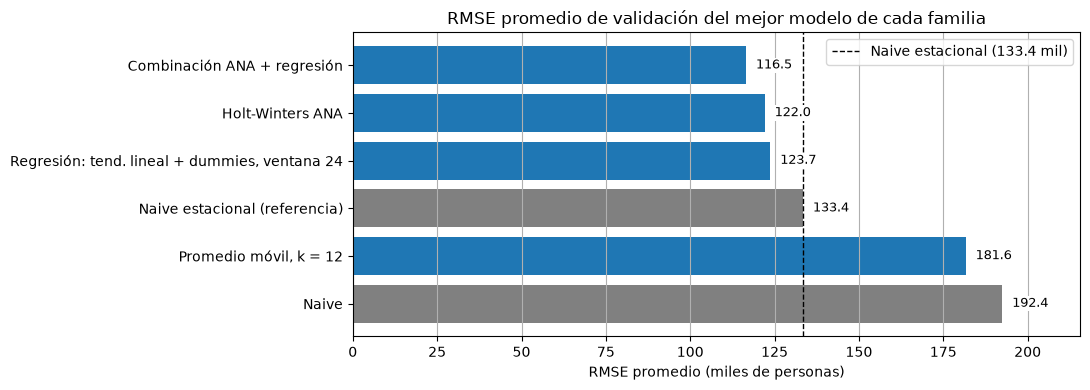

                                               RMSE promedio  MAPE promedio (%)  Cortes mejores que naive estacional
Combinación ANA + regresión                           116.47               0.92                                    3
Holt-Winters ANA                                      122.02               0.98                                    4
Regresión: tend. lineal + dummies, ventana 24         123.68               0.94                                    3
Naive estacional (referencia)                         133.36               1.05                                    0
Promedio móvil, k = 12                                181.58               1.38                                    0
Naive                                                 192.42               1.41                                    1

RMSE por corte (miles):
                   Naive estacional  HW adit. sin tend. (ANA)  Tend. lineal + dummies, ventana 24  Combinación ANA + regresión
inicio_validacion            

In [25]:
# Mejores modelos de cada familia
nombre_ma = "MA k=12"
nombre_ets = "HW adit. sin tend. (ANA)"
nombre_combinacion = "Combinación ANA + regresión"


def pronostico_ets_elegido(serie_ajuste, h):
    """Pronóstico del mejor modelo de suavización exponencial (ANA, ventana recursiva)."""
    return ajustar_ets(serie_ajuste, configuraciones_ets[nombre_ets]).forecast(h).values


def pronostico_regresion_elegida(serie_ajuste, h):
    """Pronóstico de la regresión elegida (tendencia lineal + dummies, ventana de 24 meses)."""
    return pronostico_regresion(serie_ajuste, h, config_regresion)


def pronostico_combinacion(serie_ajuste, h):
    """Promedio simple de los pronósticos del Holt-Winters ANA y de la regresión elegida."""
    return (pronostico_ets_elegido(serie_ajuste, h) + pronostico_regresion_elegida(serie_ajuste, h)) / 2


validacion[nombre_combinacion] = evaluar_validacion(pronostico_combinacion)

# Funciones de pronóstico de los modelos finalistas; se reutilizan en la prueba y en el pronóstico final
funciones_finalistas = {
    "Naive": pronostico_naive,
    "Naive estacional": pronostico_naive_estacional,
    nombre_ma: lambda serie_ajuste, h: pronostico_promedio_movil(serie_ajuste, h, k=12),
    nombre_ets: pronostico_ets_elegido,
    nombre_regresion: pronostico_regresion_elegida,
    nombre_combinacion: pronostico_combinacion,
}

# Gráfica y tabla de la validación de los finalistas (etiqueta para la gráfica: nombre en validacion)
etiquetas_finalistas = {
    "Naive": "Naive",
    "Naive estacional (referencia)": "Naive estacional",
    "Promedio móvil, k = 12": nombre_ma,
    "Holt-Winters ANA": nombre_ets,
    "Regresión: tend. lineal + dummies, ventana 24": nombre_regresion,
    "Combinación ANA + regresión": nombre_combinacion,
}
resumen_finalistas = graficar_resumen_validacion(
    etiquetas_finalistas, destacado=None,
    titulo="RMSE promedio de validación del mejor modelo de cada familia",
)
print(resumen_finalistas.round(2).to_string())

print("\nRMSE por corte (miles):")
print(error_por_corte(["Naive estacional", nombre_ets, nombre_regresion, nombre_combinacion]).round(1).to_string())

### Elección del modelo final

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| **Combinación ANA + regresión** | **116.47** | **0.92** | 3 |
| Holt-Winters ANA | 122.02 | 0.98 | 4 |
| Regresión: tend. lineal + dummies, ventana 24 | 123.68 | 0.94 | 3 |
| Naive estacional | 133.36 | 1.05 | — |
| Promedio móvil, k = 12 | 181.58 | 1.38 | 0 |
| Naive | 192.42 | 1.41 | 1 |

Los mejores modelos de la suavización exponencial y de la regresión tienen un desempeño casi igual en la validación: el Holt-Winters ANA tiene un RMSE promedio 1.66 mil personas menor (cerca de 1.4 %), y la regresión, un MAPE promedio menor. Sin embargo, sus errores no coinciden en los mismos cortes. La regresión es mejor en julio de 2016 y enero de 2017, cuando su estimación con los dos años más recientes sigue mejor el nivel de la serie, y el ANA es mejor en 2018, cuando su patrón estacional estimado con toda la historia representa mejor esos años.

Por eso, la combinación de ambos reduce el error. Su RMSE promedio es de 116.47 mil personas, cerca de 4.5 % menor que el del Holt-Winters ANA, 5.8 % menor que el de la regresión y 12.7 % menor que el del naive estacional, y su MAPE promedio, de 0.92 %, es el menor de todos los modelos evaluados. A diferencia de la ventana móvil en la suavización exponencial, cuya mejora provenía de un solo corte, la mejora de la combinación es consistente:

| Inicio del corte | Holt-Winters ANA | Regresión | Combinación |
|---|---|---|---|
| 2016-01 | 152.8 | 164.9 | **152.3** |
| 2016-07 | 67.8 | 57.5 | **53.3** |
| 2017-01 | 105.8 | **65.9** | 77.2 |
| 2017-07 | 127.6 | 128.9 | **124.3** |
| 2018-01 | **150.1** | 176.0 | 161.5 |
| 2018-07 | **128.0** | 148.9 | 130.2 |

*RMSE por corte, en miles de personas.*

La combinación tiene el menor error de los tres modelos en 3 cortes y el segundo menor en los otros 3, de modo que nunca es la peor opción. Mejora al Holt-Winters ANA en 4 de los 6 cortes y a la regresión en 5. Supera al naive estacional en 3 cortes, uno menos que el ANA, porque en enero de 2018 su error (161.5 mil) queda por encima del de la referencia (153.3 mil).

Se elige la **combinación del Holt-Winters ANA y la regresión con tendencia lineal y dummies de mes estimada con los últimos 24 meses** como modelo final, porque tiene el menor RMSE y el menor MAPE promedio de la validación y su mejora frente a cada modelo individual se repite en la mayoría de los cortes. Hay que tener en cuenta que sus dos componentes se eligieron con los mismos cortes, por lo que su error de validación es probablemente algo optimista; sin embargo, la combinación es un promedio simple, sin pesos estimados con los datos, lo que limita ese riesgo.

## 16. Evaluación en la muestra de prueba

Con el modelo final ya elegido, se usa por primera vez la muestra de prueba (enero a junio de 2019). Cada modelo finalista se ajusta con todo el entrenamiento, con su propia regla de estimación (la regresión, solo con sus últimos 24 meses), y pronostica los 6 meses de prueba sin usar ninguno de sus valores reales. Además del modelo final, se evalúan sus dos componentes, el mejor promedio móvil y las referencias naive. Estos resultados no se usan para cambiar la elección, sino para estimar el error que se puede esperar del modelo en datos que no participaron en ninguna decisión.

Error en la muestra de prueba (2019-01 a 2019-06):
                                    RMSE (miles)  MAPE (%)
Combinación ANA + regresión                62.72      0.52
Tend. lineal + dummies, ventana 24         65.20      0.49
Naive estacional                          103.75      0.95
HW adit. sin tend. (ANA)                  108.16      0.83
MA k=12                                   225.31      1.60
Naive                                     256.90      1.77

Valores reales, pronósticos y errores (miles de personas):
               Real  Combinación ANA + regresión  HW adit. sin tend. (ANA)  Tend. lineal + dummies, ventana 24  Naive estacional  Error Combinación ANA + regresión  Error HW adit. sin tend. (ANA)  Error Tend. lineal + dummies, ventana 24
mes                                                                                                                                                                                                                                          


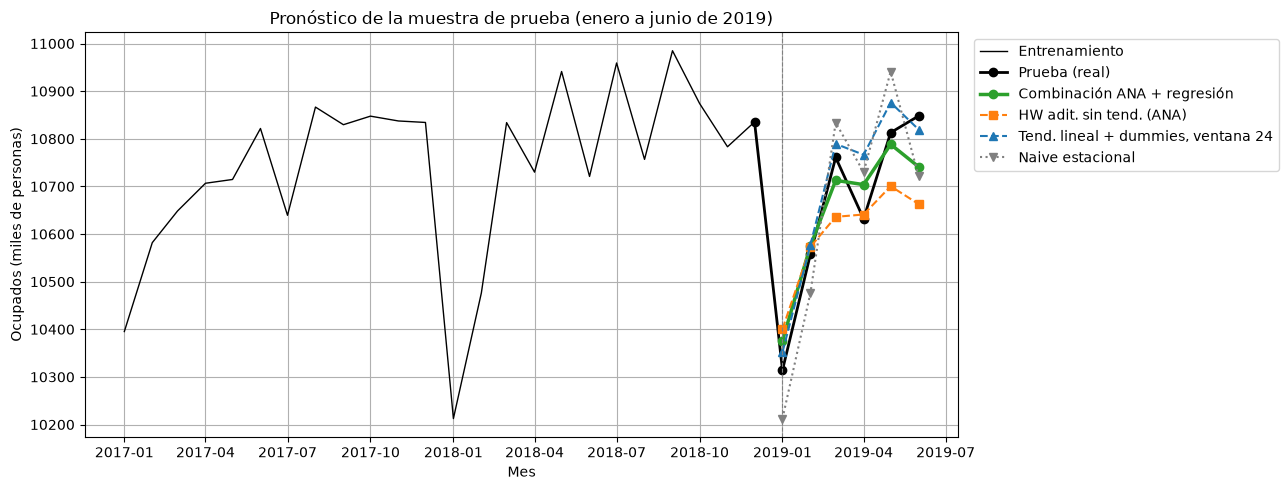

In [26]:
# Modelo final elegido en la validación
modelo_final = nombre_combinacion

# Cada finalista se ajusta con el entrenamiento y pronostica enero a junio de 2019
pronosticos_prueba = pd.DataFrame(
    {nombre: funcion(train, horizonte) for nombre, funcion in funciones_finalistas.items()},
    index=test.index,
)

metricas_prueba = pd.DataFrame(
    {nombre: calcular_metricas(test, pronosticos_prueba[nombre]) for nombre in pronosticos_prueba}
).T.rename(columns={"rmse": "RMSE (miles)", "mape": "MAPE (%)"}).sort_values("RMSE (miles)")
print("Error en la muestra de prueba (2019-01 a 2019-06):")
print(metricas_prueba.round(2).to_string())

# Valores reales, pronósticos y errores del modelo final y de sus componentes
modelos_prueba = [modelo_final, nombre_ets, nombre_regresion, "Naive estacional"]
tabla_prueba = pd.concat([test.rename("Real"), pronosticos_prueba[modelos_prueba]], axis=1)
for nombre in [modelo_final, nombre_ets, nombre_regresion]:
    tabla_prueba[f"Error {nombre}"] = tabla_prueba["Real"] - tabla_prueba[nombre]
print("\nValores reales, pronósticos y errores (miles de personas):")
print(tabla_prueba.round(1).to_string())

# Gráfica de los pronósticos de la prueba. La línea real se dibuja desde el último mes
# de entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
estilos_prueba = {
    modelo_final: dict(color="C2", linewidth=2.5, marker="o"),
    nombre_ets: dict(color="C1", linestyle="--", marker="s"),
    nombre_regresion: dict(color="C0", linestyle="--", marker="^"),
    "Naive estacional": dict(color="gray", linestyle=":", marker="v"),
}
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.loc["2017":], color="black", linewidth=1, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), color="black", linewidth=2, marker="o", label="Prueba (real)")
for nombre, estilo in estilos_prueba.items():
    ax.plot(pronosticos_prueba[nombre], label=nombre, **estilo)
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Pronóstico de la muestra de prueba (enero a junio de 2019)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
# Leyenda fuera del área de datos para no tapar la serie
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid()
plt.tight_layout()
plt.show()

### Resultados en la muestra de prueba

| Modelo | RMSE (miles) | MAPE (%) |
|---|---|---|
| **Combinación ANA + regresión** | **62.72** | 0.52 |
| Regresión: tend. lineal + dummies, ventana 24 | 65.20 | **0.49** |
| Naive estacional | 103.75 | 0.95 |
| Holt-Winters ANA | 108.16 | 0.83 |
| Promedio móvil, k = 12 | 225.31 | 1.60 |
| Naive | 256.90 | 1.77 |

El modelo final obtiene el menor RMSE en la prueba, 62.72 mil personas, cerca de 40 % menos que el naive estacional, y un MAPE de 0.52 %, apenas mayor que el de la regresión. Los resultados de la prueba confirman el orden de la validación entre las familias de modelos: la combinación y sus dos componentes superan al promedio móvil y al naive, y el promedio móvil vuelve a tener el peor desempeño entre los modelos que no son referencias, porque pronostica un valor casi constante y no reproduce la caída de enero.

La tabla de errores mensuales muestra por qué la combinación reduce el error. El Holt-Winters ANA subestima marzo, mayo y junio (errores de 124.6, 112.5 y 185.1 mil personas), porque al no tener tendencia pronostica entre 10,636 y 10,701 mil personas en esos meses, mientras que la serie subió hasta cerca de 10,850 mil. La regresión, en cambio, parte del nivel reciente de la serie y sobreestima levemente la mayoría de los meses, con su mayor error en abril (-134.5 mil), cuando el número de ocupados bajó frente a marzo. Como los errores de los dos modelos tienen con frecuencia signos opuestos, se compensan en el promedio: en marzo, por ejemplo, el ANA se equivoca en 124.6 mil y la regresión en -28.6 mil, y la combinación en 48.0 mil. El mayor error de la combinación es el de junio (106.8 mil), menor que el mayor error de cada uno de sus componentes.

En la prueba, la regresión obtiene un error muy cercano al de la combinación y bastante menor que el del Holt-Winters ANA (65.20 frente a 108.16 mil), mientras que en la validación los dos componentes tuvieron un error casi igual. La prueba es un solo periodo de 6 meses, y el RMSE de la combinación está por debajo del menor error que obtuvo en los cortes de validación (53.3 a 161.5 mil, con un promedio de 116.47), lo que indica que fue un periodo favorable para el modelo. Por eso, la elección no se modifica a partir de la prueba, y el error esperado del modelo se toma de la validación.

## 17. Pronóstico de los próximos 6 meses

Para pronosticar julio a diciembre de 2019, cada componente del modelo final se ajusta con la serie completa, de enero de 2001 a junio de 2019, con la misma regla de estimación que se usó en la validación y en la prueba: el Holt-Winters ANA estima sus parámetros y estados con toda la serie disponible, y la regresión se estima solo con los últimos 24 meses, de julio de 2017 a junio de 2019. El pronóstico final es el promedio de los dos pronósticos.

Para la combinación no existe una fórmula del intervalo de predicción, y además los errores de la regresión mostraron autocorrelación y varianza no constante (sección 14), lo que hace que los intervalos basados en esos supuestos sean demasiado estrechos. Por eso, el intervalo se construye con los errores que el modelo final ha cometido en la historia de la serie: desde cada mes de origen, a partir del mes 24, los dos componentes se ajustan con los datos disponibles hasta ese mes y la combinación pronostica los 6 meses siguientes. Esto da, para cada horizonte $h = 1, \dots, 6$, una muestra de errores de pronóstico reales, y sus percentiles 2.5 y 97.5, sumados al pronóstico puntual, forman el intervalo empírico del 95 % para ese horizonte.

Errores históricos del modelo final por horizonte (orígenes de 2002-12 a 2018-12, miles de personas):
   errores  media  desviacion  percentil_2_5  percentil_97_5
h                                                           
1      193   10.5       139.7         -247.4           280.0
2      193   19.9       147.4         -282.0           294.2
3      193   27.8       158.6         -312.2           302.2
4      193   34.5       169.2         -313.9           322.1
5      193   41.1       176.8         -296.0           358.4
6      193   49.2       181.1         -331.6           404.6

Pronóstico de julio a diciembre de 2019 (miles de personas):
            Pronóstico  Límite inferior 95 %  Límite superior 95 %  Holt-Winters ANA  Regresión  Ancho del intervalo
mes                                                                                                                 
2019-07-01     10860.7               10613.3               11140.7           10878.3    10843.0                527

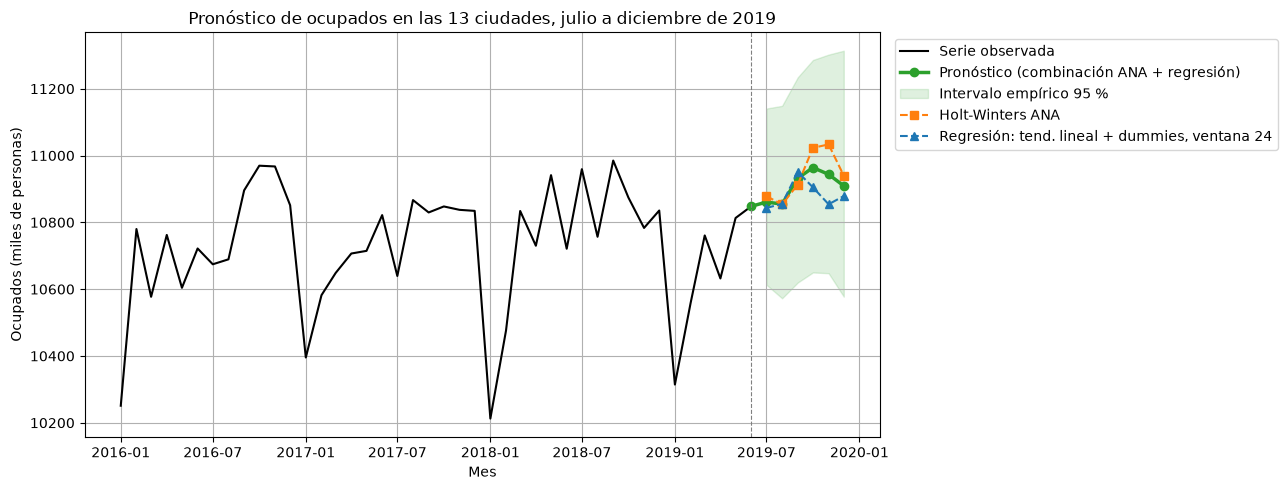

In [27]:
# Pronóstico de julio a diciembre de 2019: cada componente se ajusta con la serie completa
# con su propia regla de estimación, y el modelo final es el promedio de ambos
fechas_pronostico = fechas_siguientes(ocupados, horizonte)
pronostico_final = pd.DataFrame(
    {nombre: funciones_finalistas[nombre](ocupados, horizonte) for nombre in [modelo_final, nombre_ets, nombre_regresion]},
    index=fechas_pronostico,
)

# Errores históricos del modelo final por horizonte: desde cada mes de origen (desde el mes 24),
# los dos componentes se ajustan con los datos disponibles hasta ese mes y se pronostican los 6
# siguientes. Se usa toda la serie, incluidos los meses de prueba, porque la evaluación del modelo
# ya terminó y aquí solo se mide su incertidumbre.
filas = []
for origen in range(24, len(ocupados) - horizonte + 1):
    serie_ajuste = ocupados.iloc[:origen]
    pronostico = pronostico_combinacion(serie_ajuste, horizonte)
    reales = ocupados.iloc[origen:origen + horizonte].values
    for paso in range(horizonte):
        filas.append({"origen": serie_ajuste.index[-1], "h": paso + 1, "error": reales[paso] - pronostico[paso]})
errores_horizonte = pd.DataFrame(filas)

resumen_horizonte = errores_horizonte.groupby("h")["error"].agg(
    errores="size",
    media="mean",
    desviacion="std",
    percentil_2_5=lambda error: error.quantile(0.025),
    percentil_97_5=lambda error: error.quantile(0.975),
)
print(f"Errores históricos del modelo final por horizonte (orígenes de {errores_horizonte['origen'].min():%Y-%m} "
      f"a {errores_horizonte['origen'].max():%Y-%m}, miles de personas):")
print(resumen_horizonte.round(1).to_string())

# Tabla del pronóstico final con su intervalo empírico del 95 % y los pronósticos de sus componentes
tabla_pronostico = pd.DataFrame({
    "Pronóstico": pronostico_final[modelo_final],
    "Límite inferior 95 %": pronostico_final[modelo_final] + resumen_horizonte["percentil_2_5"].values,
    "Límite superior 95 %": pronostico_final[modelo_final] + resumen_horizonte["percentil_97_5"].values,
    "Holt-Winters ANA": pronostico_final[nombre_ets],
    "Regresión": pronostico_final[nombre_regresion],
})
tabla_pronostico["Ancho del intervalo"] = tabla_pronostico["Límite superior 95 %"] - tabla_pronostico["Límite inferior 95 %"]
tabla_pronostico.index.name = "mes"
print("\nPronóstico de julio a diciembre de 2019 (miles de personas):")
print(tabla_pronostico.round(1).to_string())

# Gráfica del pronóstico final con su intervalo y los pronósticos de sus componentes
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ocupados.loc["2016":], color="black", linewidth=1.5, label="Serie observada")
ax.plot(pd.concat([ocupados.iloc[-1:], tabla_pronostico["Pronóstico"]]), color="C2", linewidth=2.5,
        marker="o", label="Pronóstico (combinación ANA + regresión)")
ax.fill_between(tabla_pronostico.index, tabla_pronostico["Límite inferior 95 %"],
                tabla_pronostico["Límite superior 95 %"], color="C2", alpha=0.15, label="Intervalo empírico 95 %")
ax.plot(tabla_pronostico["Holt-Winters ANA"], color="C1", linestyle="--", marker="s", label="Holt-Winters ANA")
ax.plot(tabla_pronostico["Regresión"], color="C0", linestyle="--", marker="^",
        label="Regresión: tend. lineal + dummies, ventana 24")
ax.axvline(ocupados.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Pronóstico de ocupados en las 13 ciudades, julio a diciembre de 2019")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid()
plt.tight_layout()
plt.show()

### Pronóstico de julio a diciembre de 2019

| Mes | Pronóstico (miles) | Intervalo empírico 95 % | Ancho del intervalo | Holt-Winters ANA | Regresión |
|---|---|---|---|---|---|
| 2019-07 | 10,860.7 | 10,613.3 – 11,140.7 | 527.4 | 10,878.3 | 10,843.0 |
| 2019-08 | 10,854.6 | 10,572.6 – 11,148.8 | 576.1 | 10,853.8 | 10,855.4 |
| 2019-09 | 10,932.0 | 10,619.8 – 11,234.1 | 614.3 | 10,912.9 | 10,951.0 |
| 2019-10 | 10,963.8 | 10,650.0 – 11,285.9 | 636.0 | 11,023.0 | 10,904.7 |
| 2019-11 | 10,943.7 | 10,647.7 – 11,302.1 | 654.4 | 11,033.3 | 10,854.1 |
| 2019-12 | 10,909.2 | 10,577.6 – 11,313.8 | 736.2 | 10,939.7 | 10,878.6 |

El modelo final pronostica entre 10,855 y 10,964 mil personas ocupadas en el segundo semestre de 2019, con un promedio de 10,911 mil. El pronóstico parte de un nivel cercano al de junio de 2019 (10,848.0 mil) y alcanza su valor más alto en octubre.

Los dos componentes coinciden en el nivel y en los primeros meses: entre julio y septiembre sus pronósticos difieren en menos de 40 mil personas. La diferencia está en el último trimestre. El Holt-Winters ANA, con un patrón estacional estimado con toda la historia, pronostica los valores más altos en octubre y noviembre, como en la descomposición de la sección 4. La regresión, que estima los efectos de mes solo con los dos últimos años, en los que septiembre fue en promedio el mes más alto del segundo semestre, pronostica valores menores para octubre y noviembre. La mayor diferencia entre ambos es la de noviembre, de 179.2 mil personas, y el pronóstico final queda en un punto intermedio.

El intervalo empírico del 95 % se amplía con el horizonte, de 527 mil personas de ancho en julio a 736 mil en diciembre, y es asimétrico: a 6 meses va de 331.6 mil por debajo a 404.6 mil por encima del pronóstico. La asimetría se explica porque la media de los errores históricos es positiva y crece con el horizonte, de 10.5 a 49.2 mil personas: entre 2003 y 2015, cuando la serie crecía, la combinación tendía a subestimarla, sobre todo por el componente sin tendencia. El intervalo incluye también los errores del periodo 2006-2008, en el que fueron mayores. Si la serie se mantiene estable como desde 2016, el intervalo puede ser algo más ancho de lo necesario, en particular en su límite superior; aun así, refleja la incertidumbre que el modelo ha tenido en la práctica.

## 18. Conclusiones y limitaciones

### Conclusiones

- La serie de ocupados de las 13 ciudades crece de forma casi lineal entre 2001 y 2015 y se estanca desde 2016, con una estacionalidad anual marcada: una caída fuerte en enero y los valores más altos en el último trimestre. El cambio de régimen de 2016 fue el factor que más determinó el desempeño de los modelos de las tres familias.
- La estacionalidad es el componente más importante para pronosticar esta serie a 6 meses. El naive estacional reduce el RMSE del naive en cerca de 31 %, ningún promedio móvil lo supera (el mejor, de 12 meses, tiene un RMSE de 181.58 mil), y agregar la estacionalidad a la suavización exponencial simple reduce su error en cerca de 40 %.
- En la suavización exponencial, el mejor modelo es el Holt-Winters aditivo sin tendencia (ANA), con un RMSE de validación de 122.02 mil y un MAPE de 0.98 %. Las tendencias sin amortiguar empeoran el pronóstico, porque extienden el crecimiento anterior a 2016, y estimar el modelo solo con los años recientes no lo mejora de forma consistente, porque los parámetros de suavización ya lo adaptan a la información reciente.
- En la regresión, las tendencias polinómicas estimadas con toda la historia no superan al naive estacional, aunque tienen un $R^2$ mayor a 0.96, y los polinomios de grado alto reducen el error solo pronosticando caídas que los datos no muestran. El aspecto decisivo fue el periodo de estimación: la tendencia lineal con dummies de mes estimada con los últimos 24 meses redujo el RMSE de validación de 361.44 a 123.68 mil personas. Los términos de Fourier y la escala logarítmica no mejoraron el pronóstico.
- Los errores de la regresión elegida no tienen un sesgo apreciable y no se rechaza su normalidad, pero están autocorrelacionados y tienen periodos de mayor variabilidad (comportamiento ARCH), por lo que los intervalos de MCO son demasiado estrechos: en los pronósticos a un mes contuvieron el valor real en el 90.1 % de los casos, frente al 95 % nominal.
- En la validación, los mejores modelos de la suavización exponencial y de la regresión tuvieron un desempeño casi igual, pero se equivocaron en cortes distintos. Su combinación, el promedio simple de ambos pronósticos, obtuvo el menor error de todos los modelos evaluados (RMSE de 116.47 mil y MAPE de 0.92 %, cerca de 12.7 % menos de RMSE que el naive estacional), nunca fue la peor de las tres opciones en ningún corte y se eligió como modelo final. En la prueba, de enero a junio de 2019, obtuvo un RMSE de 62.72 mil y un MAPE de 0.52 %, frente a 103.75 mil y 0.95 % del naive estacional.
- Para julio a diciembre de 2019 se pronostica un número de ocupados entre 10,855 y 10,964 mil personas, con un promedio de 10,911 mil y el valor más alto en octubre, con un intervalo empírico del 95 % que se amplía de 527 mil personas de ancho en julio a 736 mil en diciembre.
- Dadas las limitaciones siguientes, el pronóstico es más útil como un rango que como un valor puntual, y conviene volver a estimar el modelo cada vez que se publique un nuevo mes, para que el nivel del Holt-Winters y la ventana de la regresión incorporen la información más reciente.

### Limitaciones

- **Supuestos de los errores.** Los errores de la regresión no se comportan como ruido blanco: la autocorrelación indica una dinámica de corto plazo que una regresión sobre el tiempo no captura y que requeriría modelos que relacionen cada error con los anteriores. Por eso, los errores estándar y los p-valores de sus coeficientes no son confiables, y los intervalos del pronóstico se construyeron con los errores observados y no con fórmulas basadas en esos supuestos.
- **Cambio de régimen.** Los dos componentes suponen, de formas distintas, que el comportamiento reciente se mantiene: el Holt-Winters ANA no tiene tendencia, y la regresión extiende la pendiente de los dos últimos años. Si la serie vuelve a crecer o a caer con fuerza, ambos tardarán en ajustarse, como le ocurrió a la regresión en el corte de enero de 2016 y al ANA en la prueba, cuando subestimó el aumento de 2019. Una alternativa no evaluada es una tendencia lineal por tramos, que permite cambiar la pendiente sin descartar datos, aunque no reestima el nivel ni los efectos de mes con los años recientes, como sí lo hace la ventana móvil.
- **Patrón estacional.** Los componentes estiman el patrón estacional de forma opuesta: el ANA lo mantiene fijo ($\gamma = 0$) con toda la historia, aunque la caída de enero se hizo más profunda en los últimos años, y la regresión estima cada efecto de mes con solo dos observaciones, por lo que un mes atípico desplaza el efecto del año siguiente. Su principal desacuerdo, en octubre y noviembre de 2019, indica que la forma del último trimestre es la parte más incierta del pronóstico.
- **Periodo de evaluación.** Los 6 cortes de validación corresponden a 2016-2018, un periodo de tendencia casi plana que favoreció a los modelos sin tendencia o estimados con pocos años, y la prueba es un solo semestre, que resultó favorable para el modelo. Las diferencias entre los mejores modelos son pequeñas frente a la variación de los errores entre cortes.
- **Selección con los mismos cortes.** Se compararon más de 200 configuraciones con los mismos 6 cortes de validación, por lo que el error de validación del modelo elegido es probablemente algo optimista.
- **Intervalo empírico.** Se construyó con los errores de toda la historia, incluidos los años de crecimiento y el periodo 2006-2008, por lo que puede ser más ancho de lo necesario si la variabilidad actual es menor. Además, cada percentil se estima con pocas observaciones en las colas, cerca de 5 de 193 errores por horizonte.
- **Modelo univariado y agregado.** El pronóstico solo usa la historia de la serie, por lo que no puede anticipar cambios causados por factores externos, como la actividad económica o la política laboral, y corresponde al total de las 13 ciudades, sin permitir conclusiones sobre cada ciudad.